# Simulação de Epidemias em Redes
**Autores:** _Rafael Gontijo_, _Rudá Brandão_

**Resumo.** Simulamos o SIS discreto em redes complexas. Na rede ER da Q1 ($N=10^4$, $\langle k\rangle\approx20$), a epidemia persiste para $R_0>1$ e se extingue para $R_0\le1$, como prevê o campo médio. A prevalência simulada fica abaixo de $1-1/R_0$, e quase toda a diferença vem da linearização da probabilidade de infecção. Na rede livre de escala (Q2, $\gamma=2{,}5$), a epidemia persiste mesmo com $R_0^{hom}<1$: o limiar é dado por $\langle k\rangle/\langle k^2\rangle\approx1/\lambda_1$, cerca de um terço do da ER, e a transição é gradual.

## Guia de uso do notebook (célula de estudo — removida no PDF)

**Convenção de tags** (View → Cell Toolbar → Tags):
| Tag | Efeito na exportação final |
|---|---|
| `study` | célula **removida** (rascunhos, anotações, checklists) |
| `hide-code` | código **oculto**, saída (figuras/tabelas) mantida |
| _(sem tag)_ | aparece normalmente |

**Orçamento de páginas (PDF):** 1 página por questão, sem contar anexos. Sugestão: Métodos + Declaração de IA ≤ 1 pág. (confirmar com o professor se contam); Q1, Q2, Q3 ≤ 1 pág. cada; código vai em anexo.

**Regras de ouro**
- Rodar sempre com *Restart & Run All* antes de exportar.
- Resultados pesados vão para `results/` (cache); o notebook relê do disco se existir.
- Toda figura: eixos rotulados, unidades, legenda, `savefig` em `figs/`.
- Nenhuma semente "solta": tudo derivado de `SEED_BASE` (célula de parâmetros).

**Checklist global**
- [ ] Declaração de IA preenchida
- [ ] Sementes informadas
- [ ] ⟨k⟩, ⟨k²⟩ medidos para cada rede (ER, SF)
- [ ] Declarado: rede fixa ou várias realizações
- [ ] 100 execuções por conjunto de parâmetros, T ≥ 500
- [ ] Extintas (fração + tempo típico), ρ(t) condicionado + faixa p10–p90 em cada caso
- [ ] Opcionais (+10%): Q1(d), média incondicional, 2.4

## Declaração de contribuição de IA
- Ferramenta(s) usada(s): Claude
- Contribuição de LLM: Geração de template para o trabalho, revisão de texto, auxílio de pesquisa, formatação das tabelas/figuras do relatório, rascunho do resumo, conferência númerica de resultados das questões, limpeza de branch, merge dos notebooks.
- Validação feita pelos autores: Todas as implementações e contas foram feitas a mão

## Configuração e reprodutibilidade

In [1]:
# Imports
import os, json, time, pickle, platform
import numpy as np
import scipy
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse.linalg import eigsh
from scipy.optimize import brentq
from scipy import stats
import pandas as pd


In [2]:
# Parâmetros globais fixados pelo enunciado
N = 10_000              # número de nós (padrão do enunciado)
T = 500            		# horizonte (mínimo)
N_RUNS = 100       		# execuções por rede por conjunto de parâmetros
N_SEEDS_INFECTED = 5	# número inicial de infectados
T_AVG = 100        		# janela da prevalência quase-estacionária
EPS = 1e-3         		# alternativa do critério de extinção (Q3)

SEED_BASE = 42   		# SEED inicial para as simulações
# Sementes: redes geradas com SEED_BASE; o lote do caso i (ordem dos dicionários de casos) usa SEED_BASE + i

# Organização de arquivos
for d in ["figs", "results"]:
    os.makedirs(d, exist_ok=True)

In [3]:
# Estilo de figuras
plt.rcParams.update({
    # Tamanho e resolução
    "figure.figsize": (6.5, 2.4),     # largura útil da página; ajuste a altura por figura
    "figure.dpi": 200,                # resolução da imagem embutida no PDF
    "savefig.dpi": 300,               # arquivo salvo / PDF final
    "savefig.bbox": "tight",          # corta margens em branco
    "figure.constrained_layout.use": True,  # evita rótulos sobrepostos

    # Fontes (legíveis em figura pequena)
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "mathtext.fontset": "cm",         # símbolos como β, μ, ρ* no estilo LaTeX
    "font.family": "serif",           # combina com o texto do PDF

    # Linhas e marcadores
    "lines.linewidth": 1.5,
    "lines.markersize": 4,

    # Eixos e grade
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,

    # Legenda
    "legend.frameon": False,

    # Vetorial limpo no PDF (fontes editáveis, sem Type 3)
    "pdf.fonttype": 42,
})

In [4]:
# Registro de ambiente (vai para o relatório)
print("Python", platform.python_version(), "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| networkx", nx.__version__)
print("SEED_BASE =", SEED_BASE)
T_INICIO = time.time()  # início da execução, para o tempo total (célula final)

Python 3.14.3 | numpy 2.5.5 | scipy 1.18.1 | networkx 3.7
SEED_BASE = 42


### Funções comuns (esqueleto — implementar)

In [5]:
# ---------- Avaliação de redes ----------
def medir_rede(G: nx.Graph):
    '''Retorna dict: <k>, <k^2>, k_min, k_max, n_componentes'''
    degrees = np.array([d for _, d in G.degree()], dtype=float)
    k_1 = np.mean(degrees)
    k_2 = np.mean(degrees ** 2)
    k_min = np.min(degrees)
    k_max = np.max(degrees)
    comps = nx.number_connected_components(G)

    return {
        '<k>': k_1,
        '<k^2>': k_2,
        'k_min': k_min,
        'k_max': k_max,
        'n_comps': comps,
        'lambda_1': eigsh(nx.to_scipy_sparse_array(G, format='csr'), k=1, which='LA',
                           return_eigenvectors=False)[0]
    }        

# ---------- Simulação SIS ----------
# Versão anterior (laço explícito em Python), mantida como referência:
# def step_sis(G: nx.Graph, beta: float, mu: float, rng):
# 	'''
# 	Executa um passo do SIS para a rede, retorna o número de sussetiveis e infectados após a atualização 
# 	'''
#
# 	states = nx.get_node_attributes(G, 'Estado')
# 	next_states = states.copy()
#
# 	for no, estado in states.items():
# 		if estado == 'I':
# 			if rng.random() < mu:
# 				next_states[no] = 'S'
# 				continue
#
# 		vizinhos_inf = sum(1 for vis in G.neighbors(no) if states[vis] == 'I')
# 		if vizinhos_inf > 0:
# 			if rng.random() < 1 - (1 - beta) ** vizinhos_inf:
# 				next_states[no] = 'I'
#
# 	nx.set_node_attributes(G, next_states, 'Estado')
#
# 	return sum(1 for s in next_states.values() if s == 'S'), sum(1 for s in next_states.values() if s == 'I')
#
#


def step_sis(G: nx.Graph, beta: float, mu: float, rng):
	'''
	Executa um passo do SIS (atualização síncrona) e retorna
	(num de suscetíveis, num de infectados) após a atualização.

	Versão vetorizada.
	'''

	n = G.number_of_nodes()
	if n == 0:
		return 0, 0

	cache = G.graph.get('_sis_estrutura')
	if (cache is None or cache[0] != n
			or cache[3][0] is not G.nodes[cache[1][0]]):   # grafo copiado: cache inválido
		nos = list(G.nodes)
		A = nx.to_scipy_sparse_array(G, format='csr', nodelist=nos)
		dicionarios = [G.nodes[u] for u in nos]
		cache = (n, nos, A, dicionarios)
		G.graph['_sis_estrutura'] = cache
	_, nos, A, dicionarios = cache

	# Estado no início do passo (True = infectado)
	infectado = np.fromiter((d['Estado'] == 'I' for d in dicionarios),
							dtype=bool, count=n)
	
	recupera = infectado & (rng.random(n) < mu)
	m = A @ infectado.astype(np.int8)  
	infecta = ~infectado & (rng.random(n) < 1 - (1 - beta) ** m)
	novo = (infectado & ~recupera) | infecta

	# Sincroniza apenas os nós que mudaram de estado (poucos por passo)
	for i in np.flatnonzero(novo != infectado):
		dicionarios[i]['Estado'] = 'I' if novo[i] else 'S'

	n_infectados = int(novo.sum())
	return n - n_infectados, n_infectados


def simular_sis(G: nx.Graph, beta: float, mu: float, T: int, rng, imunizados=None,
                n_inicial=N_SEEDS_INFECTED, return_seed_degrees=False):
	'''
	SIS discreto síncrono (estado do passo anterior).
	Retorna: serie I(t) (len T+1), t_extincao (ou None).
	Se return_seed_degrees=True, retorna tambem a lista com o grau dos vertices
	inicialmente infectados (importante para a analise de 2.1).
	'''
	g_sim = G.copy()

	if imunizados is not None:
		g_sim.remove_nodes_from(imunizados)

	nx.set_node_attributes(g_sim, {n:"S" for n in g_sim.nodes}, "Estado")
	infected_seeds = rng.choice(list(g_sim.nodes), size=min(n_inicial, g_sim.number_of_nodes()), replace=False)
	nx.set_node_attributes(g_sim, {n:'I' for n in infected_seeds}, 'Estado')

	graus_sementes = [g_sim.degree(n) for n in infected_seeds]

	infected_history = np.zeros(T+1)
	infected_history[0] = len(infected_seeds)

	for t in range(1, T+1):
		_, I = step_sis(g_sim, beta, mu, rng)
		if I == 0:
			if return_seed_degrees:
				return infected_history, t, graus_sementes
			return infected_history, t

		infected_history[t] = I

	if return_seed_degrees:
		return infected_history, None, graus_sementes
	return infected_history, None


# ---------- Estatísticas ----------
def resumir_execucoes(series, tempos_ext, populacao, T_avg=T_AVG):
	'''
	A partir das séries I(t) de várias execuções, retornar:
	frac_extintas, tempo_tipico_extincao, rho_cond(t) (média só dos sobreviventes),
	p10(t), p90(t), rho_estacionario (média dos últimos T_avg passos nos sobreviventes),
	e (opcional) média incondicional.
	'''
	rho_mtx = np.array(series).T / populacao
	nao_ext_mask = rho_mtx[-1] != 0
	frac_extintas = 1 - np.mean(nao_ext_mask)

	tempos_ext_limpo = [t for t in tempos_ext if t is not None]
	tempo_tipico_extincao = np.mean(tempos_ext_limpo) if tempos_ext_limpo else None
	tempo_mediano_extincao = np.median(tempos_ext_limpo) if tempos_ext_limpo else None
	
	if nao_ext_mask.any():
		rho_cond = np.mean(rho_mtx[:, nao_ext_mask], axis=1)
		p10, p90 = np.quantile(rho_mtx[:, nao_ext_mask], [.1, .9], axis=1)
	else:                                  # todas as execucoes extintas: sem sobreviventes para condicionar
		rho_cond = np.full(rho_mtx.shape[0], np.nan)
		p10, p90 = rho_cond.copy(), rho_cond.copy()

	rho_est = np.mean(rho_cond[-T_avg:])
	rho_geral = np.mean(rho_mtx[-T_avg:, :])

	return {
		'frac_extintas': frac_extintas,
		'tempo_tipico_extincao': tempo_tipico_extincao,
		'tempo_mediano_extincao': tempo_mediano_extincao,
		'rho_media_serie': rho_mtx.mean(axis=1),          # média incondicional (todas as execuções)
		'frac_ativas_serie': (rho_mtx > 0).mean(axis=1),  # fração de execuções ainda com infectados
		'rho_cond_media_serie': rho_cond,
		'rho_cond_p10_serie': p10,
		'rho_cond_p90_serie': p90,
		'rho_cond_media_tavg': rho_est,
		'rho_geral_media_tavg': rho_geral,
		'populacao': populacao,
		'n_amostras': rho_mtx.shape[1],
		'n_sobreviventes': int(nao_ext_mask.sum()),
		'tam_serie': rho_mtx.shape[0],
		'tavg': T_avg
	}

def rodar_lote(G, beta, mu, rng_seed, n_runs=N_RUNS, T=T, imunizados=None,
               n_inicial=N_SEEDS_INFECTED, cache_key=None, return_seed_degrees=False):
	'''
	Roda n_runs execuções; usa cache em results/ se cache_key existir.
	Retorna as séries completas e, se return_seed_degrees=True, a lista com os
	graus das sementes iniciais de cada execução.
	'''
	# TODO: implementar cache em results/

	rng = np.random.default_rng(rng_seed)
	series, tempos, graus = list(), list(), list()
	for _ in range(n_runs):
		saida = simular_sis(G, beta, mu, T, rng, imunizados, n_inicial, return_seed_degrees)
		if return_seed_degrees:
			s, t, gs = saida
			graus.append(gs)
		else:
			s, t = saida
		series.append(s)
		tempos.append(t)

	if return_seed_degrees:
		return series, tempos, graus
	return series, tempos

# ---------- Utilidades de saída ----------
def fmt(x, f):
    """Número com vírgula decimal, como nas tabelas do relatório; '—' se não houver valor."""
    return '—' if x is None or np.isnan(x) else format(x, f).replace('.', ',')

def salvar_fig(fig, nome):
    fig.savefig('figs/' + nome + '.png')

def plot_rho_cond(resumo, ax, rotulo):
	'''ρ(t) condicionado + faixa p10–p90.'''
	ax.plot(resumo['rho_cond_media_serie'], label='média')
	ax.plot(resumo['rho_cond_p10_serie'], label='quantil 10%', ls='--', lw=1.5)
	ax.plot(resumo['rho_cond_p90_serie'], label='quantil 90%', ls='--', lw=1.5)
	ax.fill_between(np.arange(resumo['tam_serie']), resumo['rho_cond_p10_serie'], resumo['rho_cond_p90_serie'], alpha=0.2)
	ax.set_title(rotulo)
	ax.set_ylabel(r'Prevalência $\rho (t)$')
	ax.set_xlabel(r'Tempo $t$')

	return

In [6]:
# Testes rápidos (sanidade) — antes de rodar em escala
rng_teste = np.random.default_rng(SEED_BASE)
K5 = nx.complete_graph(5)

# beta = 0 -> ninguém é infectado; com mu = 1 todos os sementes se recuperam no 1º passo
serie, t_ext = simular_sis(nx.cycle_graph(50), 0.0, 1.0, 10, rng_teste)
assert t_ext == 1 and serie[0] == N_SEEDS_INFECTED

# mu = 0 -> sem recuperação: I(t) nunca diminui e, com beta = 1, toda a rede conexa é infectada
serie, t_ext = simular_sis(nx.cycle_graph(50), 1.0, 0.0, 30, rng_teste)
assert t_ext is None and np.all(np.diff(serie) >= 0) and serie[-1] == 50

# Rede pequena conferida à mão (K5, 1 semente, beta = mu = 1): atualização síncrona faz I(t) alternar
# t=0: 1 infectado -> t=1: ele se recupera e os 4 vizinhos se infectam -> t=2: os 4 se recuperam e ele se reinfecta
serie, _ = simular_sis(K5, 1.0, 1.0, 4, rng_teste, n_inicial=1)
assert list(serie) == [1, 4, 1, 4, 1]

# Medidas da rede em K5: todo vértice tem grau 4
m = medir_rede(K5)
assert m['<k>'] == 4 and m['<k^2>'] == 16 and m['k_max'] == 4 and m['n_comps'] == 1

# Resumo: 2 execuções, uma extinta em t=2 e uma com I = N constante
r = resumir_execucoes([np.array([2., 1, 0, 0]), np.full(4, 5.)], [2, None], 5, T_avg=2)
assert r['frac_extintas'] == 0.5 and r['tempo_tipico_extincao'] == 2 and r['rho_cond_media_tavg'] == 1

# Mesma semente -> mesmas séries (reprodutibilidade dos lotes)
a, _ = rodar_lote(K5, 0.3, 0.2, SEED_BASE, n_runs=3, T=20)
b, _ = rodar_lote(K5, 0.3, 0.2, SEED_BASE, n_runs=3, T=20)
assert all(np.array_equal(x, y) for x, y in zip(a, b))
print('testes de sanidade OK')


testes de sanidade OK


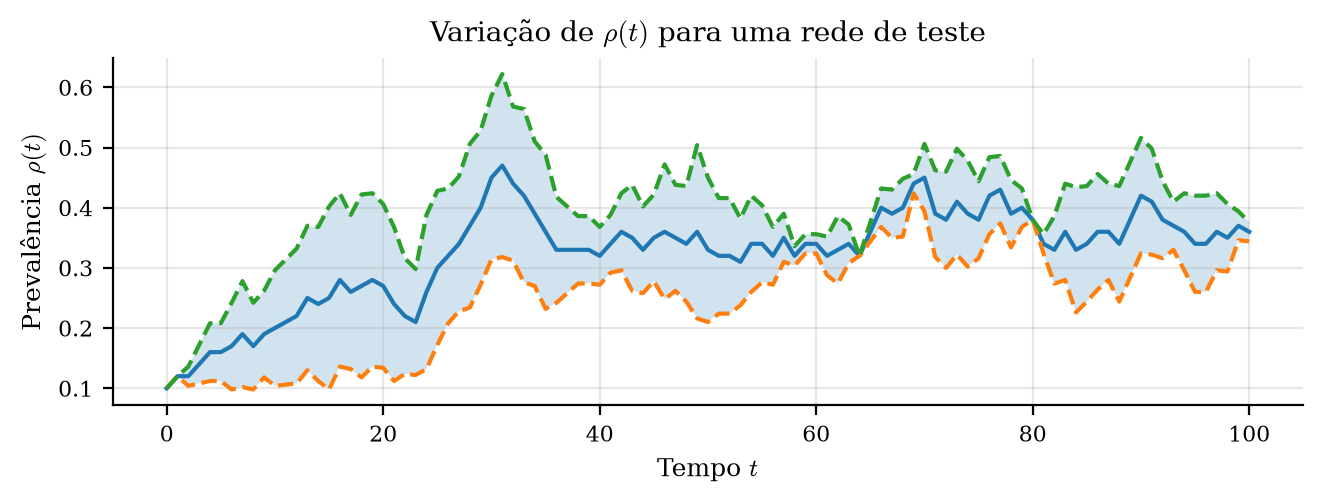

In [7]:
N_teste, p_teste = 50, 1/25
g_teste = nx.erdos_renyi_graph(N_teste, p_teste)
series_teste, tempos_teste = rodar_lote(g_teste, 0.1, 0.1, 0, 3, 100)
resumo_teste = resumir_execucoes(series_teste, tempos_teste, N_teste, 5)

f, a = plt.subplots()
plot_rho_cond(resumo_teste, a, r'Variação de $\rho(t)$ para uma rede de teste')
salvar_fig(f, 'teste_sanidade')

## 0. Métodos
**Modelo e execuções.** SIS discreto e síncrono ($\Delta t=1$): um suscetível com $m$ vizinhos infectados se infecta com probabilidade $1-(1-\beta)^m$, e um infectado se recupera com probabilidade $\mu$. Cada caso tem 100 execuções de $T=500$ passos, a partir de 5 infectados sorteados. Uma execução é extinta se $I(t)=0$ para algum $t\le T$; a prevalência estacionária $\rho^*$ é a média de $\rho$ nos últimos 100 passos, só nas sobreviventes, com faixa p10–p90.

**Tamanho da rede.** Usamos $N=10^4$, o padrão do enunciado. A execução completa, sem cache, levou cerca de 79 min nesta máquina; com os resultados guardados em `results/`, a reexecução cai para poucos minutos.

**Redes e sementes.** Cada questão usa uma rede fixa gerada com semente 42: na Q1, uma ER (`fast_gnp_random_graph`); na Q2, um configuration model com graus de $p(k)\propto k^{-2{,}5}$ em $[8,450]$, sem laços e arestas múltiplas. O lote do caso $i$ usa a semente $42+i$ (42–45 na Q1, 42–44 na Q2); na varredura de 2.3, $42+j$ (ER, a mesma rede da Q1) e $1042+j$ (SF) para o $j$-ésimo $\mu$. Versões: Python 3.14.3, NumPy 2.5.5, SciPy 1.18.1, NetworkX 3.7, Matplotlib 3.11.2; resultados em cache em `results/`.

| Rede | Método | $N$ | $\langle k\rangle$ | $\langle k^2\rangle$ | $k_{min}$–$k_{max}$ | $\lambda_1$ | Comp. |
|---|---|--|---|---|----|---|--|
| ER (Q1) | $G(N,p)$ | 10000 | 19,97 | 418,5 | 6–42 | 21,01 | 1 |
| SF (Q2) | config. | 10000 | 19,58 | 1152,7 | 7–423 | 58,71 | 1 |

In [8]:
# Rede ER da Q1 (rede fixa). Linhas da tabela de redes: copiar a saída para a tabela em "0. Métodos"
k_1 = 20
G_er = nx.fast_gnp_random_graph(N, k_1 / (N - 1), seed=SEED_BASE)
medidas_er = medir_rede(G_er)

def linha_rede(nome, metodo, G, m):
    return (f"| {nome} | {metodo} | {G.number_of_nodes()} | {fmt(m['<k>'], '.2f')} | {fmt(m['<k^2>'], '.1f')} "
            f"| {m['k_min']:.0f}–{m['k_max']:.0f} | {fmt(m['lambda_1'], '.2f')} | {m['n_comps']} |")

print(linha_rede('ER (Q1)', '$G(N,p)$', G_er, medidas_er))

| ER (Q1) | $G(N,p)$ | 10000 | 19,97 | 418,5 | 6–42 | 21,01 | 1 |


## 1. Questão 1 — Rede aleatória (Erdős–Rényi)
**Parâmetros:** $\langle k\rangle=20$, $\beta=0{,}02$; (a) $\mu=0{,}1$; (b) $\mu=0{,}3$; (c) $\mu=0{,}5$; (d, opcional) $\mu=0{,}4$.

### 1.1 Experimento
**Previsões antes de simular.** Pelo campo médio homogêneo, $R_0=\beta\langle k\rangle/\mu$ vale 4; 1,33; 0,8 e 1 em (a)–(d), e $\rho^*=\max(0,1-1/R_0)$ vale 0,75; 0,25; 0 e 0. Esperamos endemia em (a) e (b) e extinção em (c) e (d).

In [9]:
beta = 0.02
mus = [0.1, 0.3, 0.5, 0.4]
casos_q1 = dict(zip(['a', 'b', 'c', 'd'], mus))

teo_q1 = {}
for caso, mu in casos_q1.items():
    R0 = beta * k_1 / mu
    teo_q1[caso] = (R0, max(0, 1 - 1/R0))
    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0, '.3f')} | {fmt(teo_q1[caso][1], '.2f')} |")
def rho_mf_exato(mu, graus):
    '''Ponto fixo de rho = (1-mu) rho + (1-rho) <1-(1-beta rho)^k>: campo médio sem linearizar a infecção.'''
    f = lambda r: -mu * r + (1 - r) * np.mean(1 - (1 - beta * r) ** graus)
    return brentq(f, 1e-9, 1) if f(1e-9) > 0 else 0.0

graus_er = np.array([d for _, d in G_er.degree()])
mf_exato_q1 = {caso: rho_mf_exato(mu, graus_er) for caso, mu in casos_q1.items()}
# 1-(1-x)^k <= kx: sem a linearização, o ponto fixo nunca fica acima de 1 - 1/R0
assert all(mf_exato_q1[c] <= teo_q1[c][1] + 1e-9 for c in casos_q1), mf_exato_q1
mf_exato_q1


| (a) | 0,1 | 4,000 | 0,75 |
| (b) | 0,3 | 1,333 | 0,25 |
| (c) | 0,5 | 0,800 | 0,00 |
| (d) | 0,4 | 1,000 | 0,00 |


{'a': 0.7123607185764446, 'b': 0.2160617696830349, 'c': 0.0, 'd': 0.0}

In [10]:
resumos_q1 = {}

for i, (caso, mu) in enumerate(casos_q1.items()):
    arq = f'results/q1_er_s{SEED_BASE}_mu{mu}_beta{beta}_T{T}_n{N_RUNS}_N{N}.pkl'
    if os.path.exists(arq):
        with open(arq, 'rb') as f:
            series, tempos = pickle.load(f)
    else:
        series, tempos = rodar_lote(G_er, beta, mu, rng_seed=SEED_BASE + i, T=T)
        with open(arq, 'wb') as f:
            pickle.dump((series, tempos), f)
    resumos_q1[caso] = resumir_execucoes(series, tempos, N)

**Resultados** (100 execuções por caso, $T=500$). $t_{ext}$: tempo médio (mediana) de extinção das extintas; $\rho^*_{sim}$: platô das sobreviventes; MF linear: $1-1/R_0$; MF exato: o mesmo campo médio com a infecção $1-(1-\beta\rho)^k$, sem linearizar. Na figura, (c) e (d) mostram a fração de execuções ainda ativas, pois não há sobreviventes.

| Caso | $\mu$ | $R_0$ | Extintas | $t_{ext}$ média (mediana) | $\rho^*_{sim}$ | $\rho^*$ MF linear | $\rho^*$ MF exato |
|--|--|--|---|------|---|---|---|
| (a) | 0,1 | 4,00 | 0% | — | 0,705 | 0,750 | 0,712 |
| (b) | 0,3 | 1,33 | 14% | 17,7 (13,0) | 0,214 | 0,250 | 0,216 |
| (c) | 0,5 | 0,80 | 100% | 11,5 (9,0) | — | 0,000 | 0,000 |
| (d) | 0,4 | 1,00 | 94% | 45,8 (22,0) | 0,009 | 0,000 | 0,000 |

In [11]:
for caso, mu in casos_q1.items():
    r = resumos_q1[caso]
    R0, rho_teo = teo_q1[caso]
    t_ext = '—' if r['tempo_tipico_extincao'] is None else \
        f"{fmt(r['tempo_tipico_extincao'], '.1f')} ({fmt(r['tempo_mediano_extincao'], '.1f')})"
    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0, '.2f')} | {fmt(100 * r['frac_extintas'], '.0f')}% | {t_ext} "
          f"| {fmt(r['rho_cond_media_tavg'], '.3f')} | {fmt(rho_teo, '.3f')} | {fmt(mf_exato_q1[caso], '.3f')} |")

| (a) | 0,1 | 4,00 | 0% | — | 0,705 | 0,750 | 0,712 |
| (b) | 0,3 | 1,33 | 14% | 17,7 (13,0) | 0,214 | 0,250 | 0,216 |
| (c) | 0,5 | 0,80 | 100% | 11,5 (9,0) | — | 0,000 | 0,000 |
| (d) | 0,4 | 1,00 | 94% | 45,8 (22,0) | 0,009 | 0,000 | 0,000 |


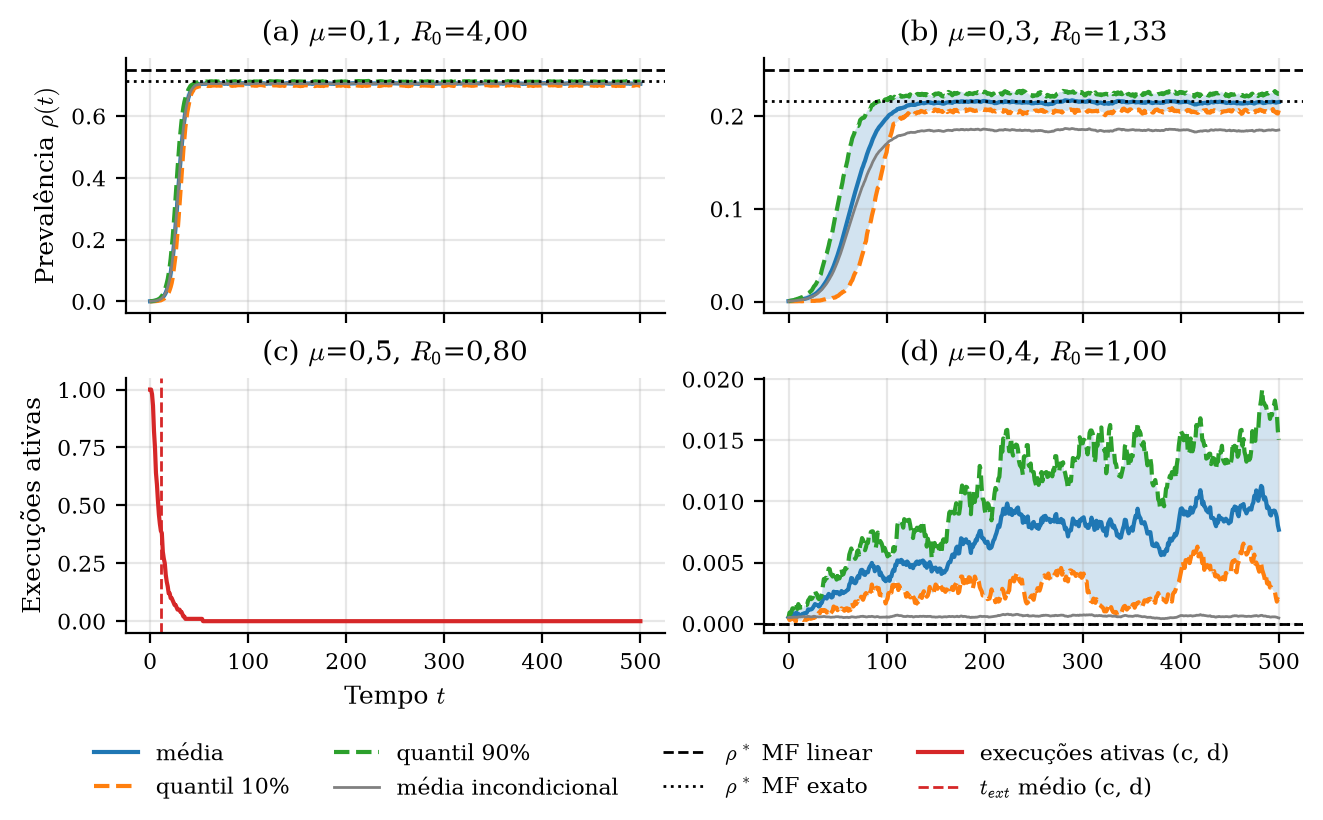

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(6.5, 4.0), sharex=True)
axs = axs.flat
for ax, (caso, mu) in zip(axs, casos_q1.items()):
    r = resumos_q1[caso]
    R0, rho_teo = teo_q1[caso]
    titulo = f'({caso}) $\\mu$={fmt(mu, "g")}, $R_0$={fmt(R0, ".2f")}'
    if r['frac_extintas'] < 1:
        plot_rho_cond(r, ax, titulo)
        ax.set_xlabel('')
        ax.plot(r['rho_media_serie'], color='gray', lw=1, label='média incondicional')
        ax.axhline(rho_teo, color='k', ls='--', lw=1, label=r'$\rho^*$ MF linear')
        ax.axhline(mf_exato_q1[caso], color='k', ls=':', lw=1, label=r'$\rho^*$ MF exato')
    else:
        ax.plot(r['frac_ativas_serie'], color='C3', label='execuções ativas (c, d)')
        ax.axvline(r['tempo_tipico_extincao'], color='C3', ls='--', lw=1, label=r'$t_{ext}$ médio (c, d)')
        ax.set_title(titulo)
        ax.set_ylabel('Execuções ativas')
        ax.set_xlabel(r'Tempo $t$')
for ax in axs[1::2]:
    ax.set_ylabel('')
linhas = axs[0].get_legend_handles_labels()
extras = axs[2].get_legend_handles_labels()
fig.legend(linhas[0] + extras[0], linhas[1] + extras[1], loc='outside lower center', ncol=4, fontsize=8)
salvar_fig(fig, 'q1_rho_cond')

**Discussão.**

- **Simulação × campo médio.** O campo médio acerta o regime nos quatro casos, mas superestima o platô: 0,705 contra 0,750 em (a) e 0,214 contra 0,250 em (b).
- **Tempo discreto.** Quase toda essa diferença vem de o mapa usar $\beta m$ no lugar de $1-(1-\beta)^m$, contando várias vezes as tentativas de infecção que caem no mesmo nó no mesmo passo. Sem essa linearização, o ponto fixo cai para 0,712 e 0,216, quase o valor simulado.
- **Correlações entre vizinhos.** O resíduo em (a) (0,705 × 0,712) é compatível com correlações dinâmicas: os vizinhos de um infectado tendem a estar infectados, e parte das tentativas se perde, enquanto o campo médio os supõe independentes.
- **Tamanho finito e 5 sementes.** Com poucos infectados, a epidemia pode morrer por acaso antes de decolar. Cada linhagem se extingue com probabilidade $\approx1/R_0$, e as cinco juntas com $(1/R_0)^5$: $0{,}75^5\approx0{,}24$ em (b), perto dos 14% observados (todos até $t=39$), e $0{,}25^5\approx10^{-3}$ em (a), onde nenhuma execução se extinguiu.
- **(opc.) Caso crítico (d).** Com $R_0=1$ o mapa decai de forma algébrica, $\rho_t\approx\rho_0/(1+\mu\rho_0t)$, e não exponencial. Nas simulações, a extinção também é lenta e tem cauda longa (mediana de 22,0 passos, máximo de 497), então o resultado depende de $T$: em $t=100$, 12% das execuções ainda estavam ativas.
- **(opc.) Média incondicional.** Em (b), a média sobre todas as execuções ($0{,}185\approx0{,}86\cdot0{,}214$) mistura as que estão no platô com as extintas e não descreve nenhuma delas; por isso $\rho^*$ é medido só nas sobreviventes.

### 1.2 Demonstração (campo médio homogêneo)
Mapa: $\rho_{t+1}=g(\rho_t)=\rho_t-\mu\rho_t+\beta\langle k\rangle\rho_t(1-\rho_t)$, com $R_0=\beta\langle k\rangle/\mu$, ou seja, $\beta\langle k\rangle=\mu R_0$.

**(1) Pontos fixos.** $\rho=g(\rho)$ equivale a $\rho\,[\mu R_0(1-\rho)-\mu]=0$, logo $\rho=0$ ou $\rho^*=1-1/R_0$. Se $R_0>1$, $\rho^*\in(0,1)$ é um segundo ponto fixo; se $R_0\le1$, $\rho^*\le0$ e o único ponto fixo em $[0,1]$ é $\rho=0$.

**(2) Estabilidade.** $g'(\rho)=1-\mu+\mu R_0(1-2\rho)$. Em zero, $g'(0)=1+\mu(R_0-1)>1$ quando $R_0>1$, então $\rho=0$ é instável. No ponto endêmico, $g'(\rho^*)=1-\mu(R_0-1)$, e $|g'(\rho^*)|<1$ equivale a $0<\mu(R_0-1)<2$. Na Q1, $\mu(R_0-1)=0{,}3$ em (a) e $0{,}1$ em (b): $\rho^*$ é estável nos dois.

**(3) Crescimento.** $\rho_{t+1}-\rho_t=\mu R_0\,\rho_t(\rho^*-\rho_t)$, que é positivo se $R_0>1$ e $0<\rho_t<\rho^*$. Logo, partindo de poucos infectados ($\rho_0=5/N=5\times10^{-4}$), $\rho_t$ cresce monotonicamente até $\rho^*$, como confirma a iteração do mapa:

| Caso | $\mu(R_0-1)$ | $g'(0)$ | $g'(\rho^*)$ | $\rho_{150}$ ($\rho_0=5/N$) | $\rho^*$ |
|---|---|---|---|---|---|
| (a) | 0,300 | 1,300 | 0,700 | 0,7500 | 0,750 |
| (b) | 0,100 | 1,100 | 0,900 | 0,2500 | 0,250 |
| (c) | -0,100 | 0,900 | — | 0,0000 | 0,000 |
| (d) | 0,000 | 1,000 | — | 0,0005 | 0,000 |

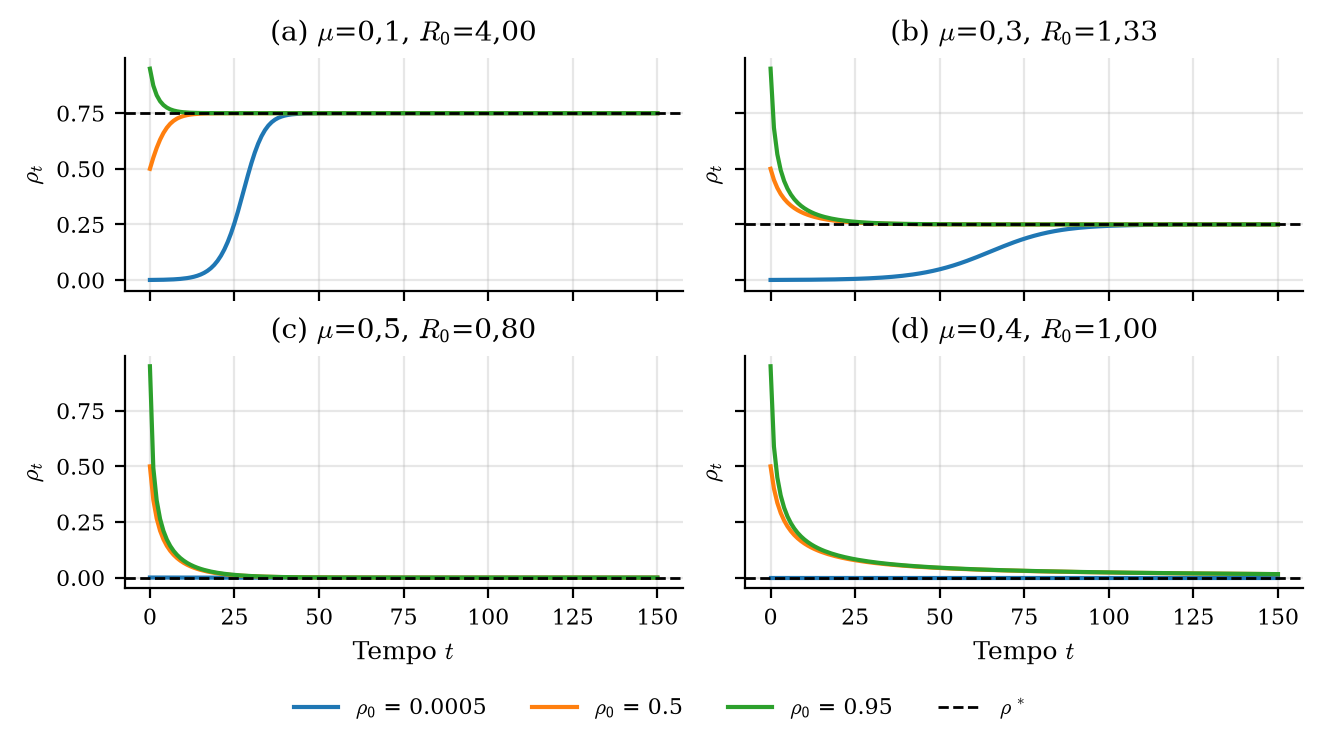

In [13]:
T_mapa = 150
rhos_0 = [N_SEEDS_INFECTED / N, 0.5, 0.95]

def iterar_mapa(rho0, mu, passos=T_mapa):
    rho = [rho0]
    for _ in range(passos):
        r = rho[-1]
        rho.append(r - mu * r + beta * k_1 * r * (1 - r))
    return np.array(rho)

fig, axs = plt.subplots(2, 2, figsize=(6.5, 3.6), sharex=True, sharey=True)
axs = axs.flat

for ax, (caso, mu) in zip(axs, casos_q1.items()):
    R0, rho_teo = teo_q1[caso]
    trajs = {rho0: iterar_mapa(rho0, mu) for rho0 in rhos_0}
    for rho0, traj in trajs.items():
        ax.plot(traj, label=rf'$\rho_0$ = {rho0:g}')
    ax.axhline(rho_teo, color='k', ls='--', lw=1, label=r'$\rho^*$')
    ax.set_title(f'({caso}) $\\mu$={fmt(mu, "g")}, $R_0$={fmt(R0, ".2f")}')
    ax.set_xlabel(r'Tempo $t$' if caso in 'cd' else '')
    ax.set_ylabel(r'$\rho_t$')

    c = mu * (R0 - 1)
    if R0 > 1:
        assert 0 < c < 2, f'rho* instável no caso ({caso})'
        assert abs(trajs[rhos_0[0]][-1] - rho_teo) < 1e-3, f'mapa não convergiu a rho* no caso ({caso})'

fig.legend(*axs[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=8)
salvar_fig(fig, 'q1_mapa')

In [14]:
# Linhas da tabela de estabilidade: copiar a saída para a tabela em "1.2 Demonstração"
for caso, mu in casos_q1.items():
    R0, rho_teo = teo_q1[caso]
    c = mu * (R0 - 1)
    rho_T = iterar_mapa(rhos_0[0], mu)[-1]
    print(f"| ({caso}) | {fmt(c, '.3f')} | {fmt(1 + c, '.3f')} | {fmt(1 - c, '.3f') if R0 > 1 else '—'} "
          f"| {fmt(rho_T, '.4f')} | {fmt(rho_teo, '.3f')} |")

| (a) | 0,300 | 1,300 | 0,700 | 0,7500 | 0,750 |
| (b) | 0,100 | 1,100 | 0,900 | 0,2500 | 0,250 |
| (c) | -0,100 | 0,900 | — | 0,0000 | 0,000 |
| (d) | 0,000 | 1,000 | — | 0,0005 | 0,000 |


**Conclusão numérica.** O mapa confirma a análise: converge para $\rho^*$ em (a) e (b) e para zero em (c) (exponencialmente) e em (d) (algebricamente). A simulação concorda no regime, mas mostra três efeitos que o mapa determinístico não tem: platô mais baixo, extinções precoces em (b) e extinção certa em (d).

## 2. Questão 2 — Rede livre de escala
**Parâmetros:** $\gamma=2{,}5$, $N=10^4$, $\langle k\rangle\approx20\ (\pm10\%)$, $\beta=0{,}01$; (a) $\mu=0{,}1$; (b) $\mu=0{,}2$; (c) $\mu=0{,}3$.

### 2.0 Geração da rede

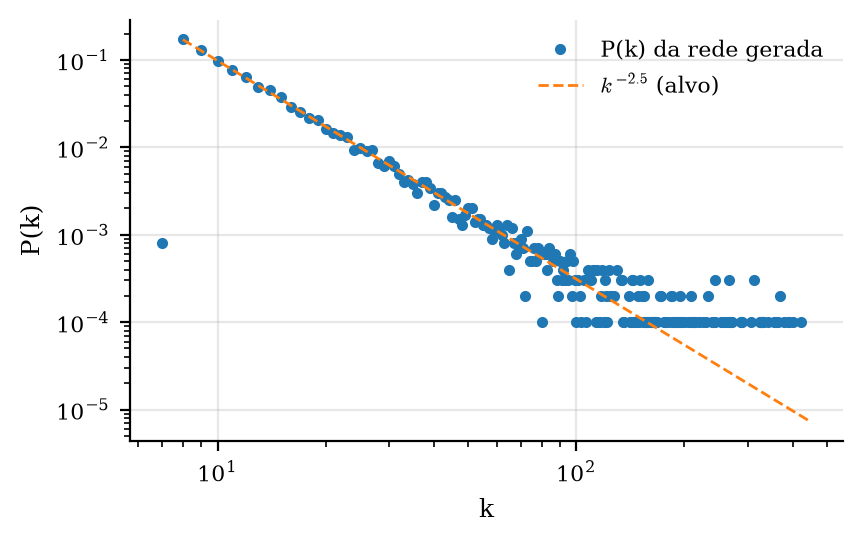

In [15]:
# Geração da rede livre de escala (configuration model "erased")
def gerar_rede_sf(N_rede, gamma=2.5, k_min=8, k_max=None, seed=SEED_BASE):
    """Sorteia N_rede graus i.i.d. de p(k) ∝ k^-gamma em [k_min, k_max] e monta a
    rede pelo configuration model; laços e arestas múltiplas são removidos."""
    if k_max is None:
        k_max = int(round(np.sqrt(N_rede * 20)))        # cutoff natural ~ sqrt(N<k>)
    ks = np.arange(k_min, k_max + 1)
    probs = ks.astype(float) ** (-gamma)
    probs /= probs.sum()

    rng_deg = np.random.default_rng(seed)
    deg_dist = rng_deg.choice(ks, size=N_rede, replace=True, p=probs)
    if deg_dist.sum() % 2:                              # soma dos graus precisa ser par
        i = rng_deg.choice(np.flatnonzero(deg_dist < k_max))
        deg_dist[i] += 1

    g = nx.Graph(nx.configuration_model(deg_dist, seed=seed))
    g.remove_edges_from(nx.selfloop_edges(g))
    return g

# Rede oficial do enunciado (N = 10^4, <k> ~ 20)
N_sf, k_min, k_max, gamma = 10_000, 8, 450, 2.5
G_sf = gerar_rede_sf(N_sf, gamma=gamma, k_min=k_min, k_max=k_max)

# P(k) medida na rede final, em log-log, com a reta k^-gamma de referência
fig_pk, ax_pk = plt.subplots(figsize=(4.2, 2.6))
hist = np.bincount([d for _, d in G_sf.degree()])
ks_med = np.nonzero(hist)[0]
ax_pk.loglog(ks_med, hist[ks_med] / N_sf, 'o', ms=3, label='P(k) da rede gerada')
kk = np.arange(k_min, k_max + 1)
probs = kk.astype(float) ** (-gamma)
probs /= probs.sum()
ax_pk.loglog(kk, probs, '--', lw=1, label=r'$k^{-2.5}$ (alvo)')
ax_pk.set_xlabel('k')
ax_pk.set_ylabel('P(k)')
ax_pk.legend()
salvar_fig(fig_pk, 'q2_pk')
plt.show()

In [16]:
# Linha da rede SF para a tabela de redes em "0. Métodos" e valores para "Rede gerada"
print(linha_rede('SF (Q2)', 'config.', G_sf, medir_rede(G_sf)))

| SF (Q2) | config. | 10000 | 19,58 | 1152,7 | 7–423 | 58,71 | 1 |


**Rede gerada.** Usamos o configuration model: sorteamos os graus de $p(k)\propto k^{-2{,}5}$ em $[8,450]$ e ligamos as pontas ao acaso. A remoção de laços e arestas múltiplas reduz alguns graus (daí $k_{min}=7$). Resultado: $\langle k\rangle=19{,}58$ (dentro dos ±10%), $\langle k^2\rangle=1152{,}7$, $k_{max}=423$, $\lambda_1=58{,}71$, rede conexa. Comparada à ER da Q1, tem $\langle k\rangle$ parecido mas $\langle k^2\rangle$ cerca de 2,8 vezes maior, por causa da cauda de hubs, e é isso que muda o limiar.

### 2.1 Experimento

In [17]:
# --- Escala de execução ------------------------------------------------------
# True  -> teste rápido, com rede pequena (para validar o código)
# False -> números oficiais do enunciado (N = 10^4, N_RUNS = 100, T = 500)
MODO_TESTE = False

if MODO_TESTE:
    N_q2, N_RUNS_q2, T_q2 = 100, 10, 200
    G_q2 = gerar_rede_sf(N_q2, gamma=gamma, k_min=k_min)
else:
    N_q2, N_RUNS_q2, T_q2 = N_sf, N_RUNS, T
    G_q2 = G_sf

medidas_q2 = medir_rede(G_q2)

beta_q2 = 0.01
casos_q2 = dict(zip(['a', 'b', 'c'], [0.1, 0.2, 0.3]))

resumos_q2, graus_sementes_q2, rho_final_q2, rho_plato_q2 = {}, {}, {}, {}

for i, (caso, mu) in enumerate(casos_q2.items()):
    arq = f'results/q2_sf_s{SEED_BASE}_N{N_q2}_mu{mu}_beta{beta_q2}_T{T_q2}_n{N_RUNS_q2}.pkl'
    if os.path.exists(arq):
        with open(arq, 'rb') as f:
            series, tempos, graus = pickle.load(f)
    else:
        series, tempos, graus = rodar_lote(
            G_q2, beta_q2, mu, rng_seed=SEED_BASE + i,
            n_runs=N_RUNS_q2, T=T_q2, return_seed_degrees=True)
        with open(arq, 'wb') as f:
            pickle.dump((series, tempos, graus), f)

    resumos_q2[caso] = resumir_execucoes(series, tempos, N_q2)
    graus_sementes_q2[caso] = np.array(graus)                        # (n_runs, n_inicial)
    rho_final_q2[caso] = np.array([s[-1] for s in series]) / N_q2    # prevalência em t = T
    rho_plato_q2[caso] = np.array([s[-T_AVG:].mean() for s in series]) / N_q2  # platô de cada execução

In [18]:
# Conferência dos lotes da Q2
print(f"N={N_q2}  <k>={medidas_q2['<k>']:.2f}  <k²>={medidas_q2['<k^2>']:.2f}  "
      f"k_min={medidas_q2['k_min']:.0f}  k_max={medidas_q2['k_max']:.0f}  "
      f"λ₁={medidas_q2['lambda_1']:.2f}  componentes={medidas_q2['n_comps']}")
for caso, mu in casos_q2.items():
    print(f"({caso}) μ={mu:g}: {resumos_q2[caso]['n_amostras']} execuções, "
          f"{fmt(100 * resumos_q2[caso]['frac_extintas'], '.0f')}% extintas")

N=10000  <k>=19.58  <k²>=1152.74  k_min=7  k_max=423  λ₁=58.71  componentes=1
(a) μ=0.1: 100 execuções, 2% extintas
(b) μ=0.2: 100 execuções, 19% extintas
(c) μ=0.3: 100 execuções, 52% extintas


**Resultados por caso** (100 execuções, $T=500$). Colunas: fração de execuções extintas até $T$; $t_{ext}$, tempo médio de extinção das extintas; $\rho^*_{sim}$, prevalência média nos últimos 100 passos das sobreviventes; $\rho^*_{hom}=\max(0,1-1/R_0^{hom})$, previsão homogênea; grau médio das 5 sementes.

| Caso | $\mu$ | $R_0^{hom}$ | Extintas | $t_{ext}$ médio | $\rho^*_{sim}$ | $\rho^*_{hom}$ | $\langle k\rangle$ sementes |
|--|--|---|---|---|---|---|----|
| (a) | 0,1 | 1,96 | 2% | 23,5 | 0,436 | 0,489 | 19,8 |
| (b) | 0,2 | 0,98 | 19% | 12,9 | 0,205 | 0,000 | 19,3 |
| (c) | 0,3 | 0,65 | 52% | 11,2 | 0,099 | 0,000 | 19,9 |

In [19]:
# Linhas da tabela de resultados da Q2 e correlações: copiar a saída para os markdowns de "2.1 Experimento"
for caso, mu in casos_q2.items():
    r = resumos_q2[caso]
    R0_hom = beta_q2 * medidas_q2['<k>'] / mu
    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0_hom, '.2f')} | {fmt(100 * r['frac_extintas'], '.0f')}% "
          f"| {fmt(r['tempo_tipico_extincao'], '.1f')} | {fmt(r['rho_cond_media_tavg'], '.3f')} "
          f"| {fmt(max(0.0, 1 - 1 / R0_hom), '.3f')} | {fmt(graus_sementes_q2[caso].mean(), '.1f')} |")
print()
# Correlações do grau médio das sementes: com rho(T) em todas as execuções (extintas = 0), com a sobrevivência
# (ponto-bisserial) e com o platô (últimos T_AVG passos) só entre as sobreviventes; p-valor entre parênteses
def corr_p(x, y):
    return '—' if len(x) < 3 or x.std() == 0 or y.std() == 0 else \
        f"{fmt(stats.pearsonr(x, y)[0], '+.2f')} ({fmt(stats.pearsonr(x, y)[1], '.2f')})"
for caso in casos_q2:
    x, y = graus_sementes_q2[caso].mean(axis=1), rho_final_q2[caso]
    viva = y > 0
    print(f"| ({caso}) | {(~viva).sum()} | {corr_p(x, y)} | {corr_p(x, viva.astype(float))} | {corr_p(x[viva], rho_plato_q2[caso][viva])} |")

| (a) | 0,1 | 1,96 | 2% | 23,5 | 0,436 | 0,489 | 19,8 |
| (b) | 0,2 | 0,98 | 19% | 12,9 | 0,205 | 0,000 | 19,3 |
| (c) | 0,3 | 0,65 | 52% | 11,2 | 0,099 | 0,000 | 19,9 |

| (a) | 2 | +0,05 (0,59) | +0,07 (0,52) | -0,20 (0,05) |
| (b) | 19 | +0,23 (0,02) | +0,22 (0,03) | +0,09 (0,41) |
| (c) | 52 | +0,28 (0,00) | +0,29 (0,00) | -0,05 (0,72) |


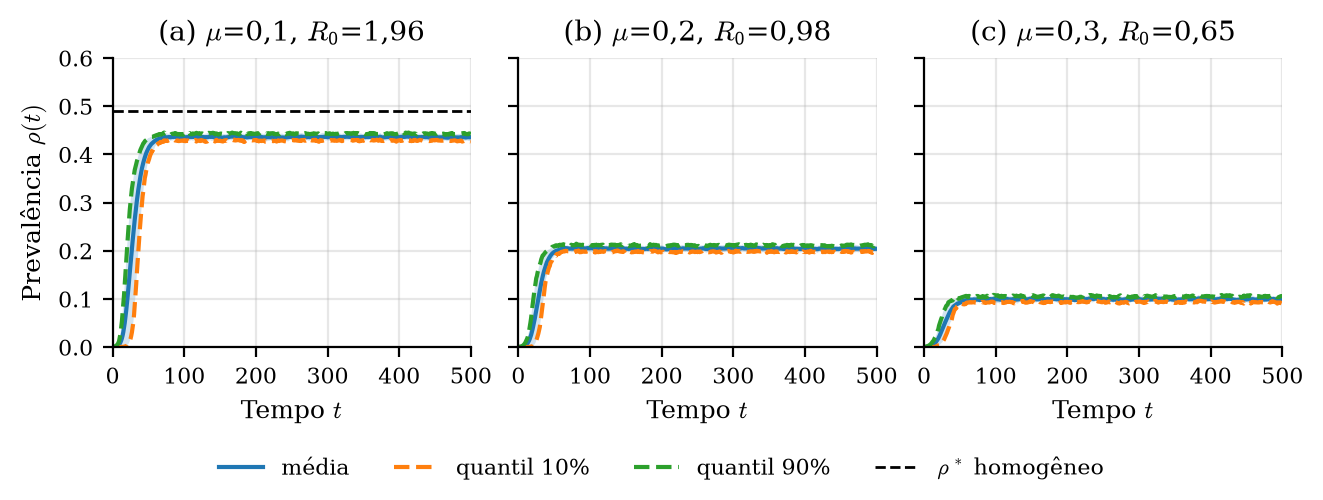

In [20]:
# ρ(t) condicionado (média + faixa p10–p90) para cada caso
fig, axs = plt.subplots(1, 3, figsize=(6.5, 2.4), sharey=True)

for ax, (caso, mu) in zip(axs, casos_q2.items()):
    r = resumos_q2[caso]
    R0_hom = beta_q2 * medidas_q2['<k>'] / mu
    rho_hom = max(0.0, 1 - 1 / R0_hom)
    titulo = f'({caso}) $\\mu$={fmt(mu, "g")}, $R_0$={fmt(R0_hom, ".2f")}'

    if r['n_sobreviventes'] > 0:
        plot_rho_cond(r, ax, titulo)
    else:
        ax.set_title(titulo)
        ax.text(0.5, 0.5, 'todas as execuções extintas', transform=ax.transAxes,
                ha='center', va='center', fontsize=7, color='0.35')
    ax.axhline(rho_hom, color='k', ls='--', lw=1, label=r'$\rho^*$ homogêneo')
    ax.set_xlim(0, r['tam_serie'] - 1)
    ax.set_ylim(0, 0.6)

for ax in axs[1:]:
    ax.set_ylabel('')
fig.legend(*axs[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=8)
salvar_fig(fig, 'q2_rho_cond')
plt.show()

**As sementes importam?** Como $\rho(T)$ vale 0 nas execuções extintas e fica perto do platô nas demais, correlacioná-lo com o grau das sementes mistura duas perguntas. Por isso separamos (Pearson, p-valor entre parênteses): **todas**, com $\rho(T)$ nas 100 execuções; **sobreviver**, com o fato de a execução chegar viva a $T$; **platô**, com a média dos últimos 100 passos, só entre as sobreviventes.

| Caso | Extintas | Todas | Sobreviver | Platô |
|---|---|---|---|---|
| (a) | 2 | +0,05 (0,59) | +0,07 (0,52) | -0,20 (0,05) |
| (b) | 19 | +0,23 (0,02) | +0,22 (0,03) | +0,09 (0,41) |
| (c) | 52 | +0,28 (0,00) | +0,29 (0,00) | -0,05 (0,72) |

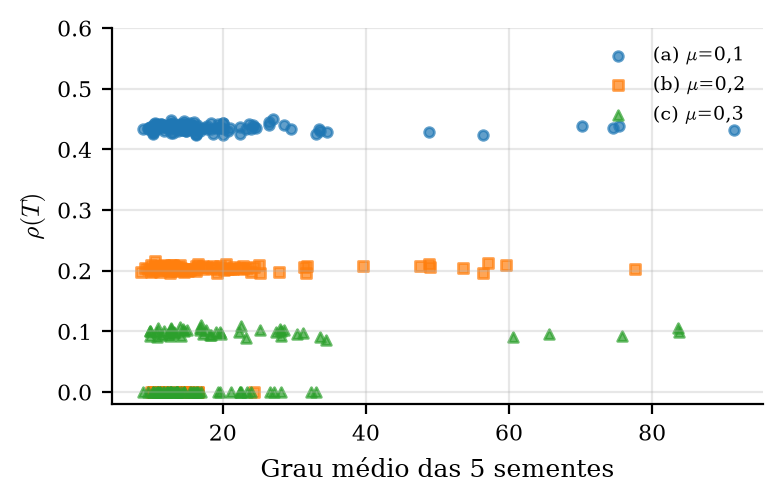

In [21]:
# Prevalência final de cada execução vs. grau médio das 5 sementes (extintas ficam em ρ(T) = 0)
fig, ax = plt.subplots(figsize=(3.8, 2.4))
marcadores = {'a': 'o', 'b': 's', 'c': '^'}
for caso, mu in casos_q2.items():
    ax.scatter(graus_sementes_q2[caso].mean(axis=1), rho_final_q2[caso], s=12, marker=marcadores[caso],
               alpha=0.7, label=f'({caso}) $\\mu$={fmt(mu, "g")}')
ax.set_xlabel('Grau médio das 5 sementes')
ax.set_ylabel(r'$\rho(T)$')
ax.set_ylim(-0.02, 0.6)
ax.legend(loc='upper right', fontsize=7)
salvar_fig(fig, 'q2_sementes')
plt.show()

**Discussão.**

- **Comportamento médio.** O campo médio homogêneo só acerta em (a), o único caso com $R_0^{hom}>1$: quase nenhuma execução se extingue (2%) e o platô (0,436) fica perto do previsto (0,489). Em (b) e (c) ele prevê extinção, mas 81% e 48% das execuções sobrevivem até $T$, com platôs de 0,205 e 0,099. A heterogeneidade dos graus sustenta a epidemia abaixo do limiar homogêneo (ver 2.2).
- **Grau das sementes.** O grau das sementes influencia, no máximo, se a epidemia decola, mas não o tamanho do platô. Sementes de grau maior tendem a evitar a extinção (+0,22 em (b), p = 0,03), mas entre as sobreviventes a correlação com o platô é fraca (+0,09, p = 0,41): depois de estabelecida, a epidemia esquece a condição inicial. O +0,23 da coluna "todas" em (b) reflete, portanto, sobretudo a sobrevivência. Em (a) há apenas 2 extintas e nenhum efeito é estimável.
- **Hubs.** A mesma tendência aparece com os hubs: se uma das sementes tem grau $\ge40$, a extinção em (b) cai de 27% para 6% (p = 0,015). Faz sentido: um hub infecta muitos vizinhos antes de se recuperar e ajuda a epidemia a passar pela fase inicial, quando ela ainda pode morrer por acaso.

### 2.2 Teoria — indicadores de limiar
Cada indicador compara $\lambda=\beta/\mu$ com um limiar: $1/\langle k\rangle=0{,}0511$ (homogêneo, ignora a variância dos graus), $\langle k\rangle/\langle k^2\rangle=0{,}0170$ (heterogêneo, campo médio por grau) e $1/\lambda_1=0{,}0170$ (quenched, usa a rede real). $R_0>1$ indica estado endêmico (end.); caso contrário, subcrítico (sub.). A última coluna é a prevalência prevista pelo campo médio heterogêneo, calculada com os graus da rede e a infecção discreta $1-(1-\beta\Theta)^k$.

| Caso | $\mu$ | $R_0^{hom}$ | $R_0^{het}$ | $R_0^{quenched}$ | Previsão hom / het / quenched | $\rho^*_{sim}$ | $\rho^*_{HMF}$ |
|--|--|---|---|---|-------|---|---|
| (a) | 0,1 | 1,96 | 5,89 | 5,87 | end. / end. / end. | 0,436 | 0,442 |
| (b) | 0,2 | 0,98 | 2,94 | 2,94 | sub. / end. / end. | 0,205 | 0,210 |
| (c) | 0,3 | 0,65 | 1,96 | 1,96 | sub. / end. / end. | 0,099 | 0,102 |

In [22]:
# Indicadores de limiar: campo médio homogêneo, heterogêneo e quenched
k1_q2 = medidas_q2['<k>']
k2_q2 = medidas_q2['<k^2>']
lam1_q2 = medidas_q2['lambda_1']

# Linhas da tabela e limiares: copiar a saída para o markdown de "2.2 Teoria"
print(f"limiares: hom {fmt(1 / k1_q2, '.4f')} | het {fmt(k1_q2 / k2_q2, '.4f')} | quenched {fmt(1 / lam1_q2, '.4f')}")


def rho_hmf(mu, graus, beta=beta_q2):
    '''Campo médio heterogêneo discreto: rho_k = q_k/(mu+q_k), q_k = 1-(1-beta Θ)^k, Θ = Σ k P(k) rho_k / <k>.'''
    def rho_k(th):
        q = 1 - (1 - beta * th) ** graus
        return q / (mu + q)
    F = lambda th: np.mean(graus * rho_k(th)) / np.mean(graus) - th
    return float(np.mean(rho_k(brentq(F, 1e-9, 1)))) if F(1e-9) > 0 else 0.0

graus_q2 = np.array([d for _, d in G_q2.degree()])
rho_hmf_q2 = {caso: rho_hmf(mu, graus_q2) for caso, mu in casos_q2.items()}
assert all(0 <= v < 1 for v in rho_hmf_q2.values())


def previsao(R0):
    return 'end.' if R0 > 1 else 'sub.'


for caso, mu in casos_q2.items():
    R0_hom = beta_q2 * k1_q2 / mu
    R0_het = beta_q2 * k2_q2 / (mu * k1_q2)
    R0_q = beta_q2 * lam1_q2 / mu
    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0_hom, '.2f')} | {fmt(R0_het, '.2f')} | "
          f"{fmt(R0_q, '.2f')} | {previsao(R0_hom)} / {previsao(R0_het)} / {previsao(R0_q)} | "
          f"{fmt(resumos_q2[caso]['rho_cond_media_tavg'], '.3f')} | {fmt(rho_hmf_q2[caso], '.3f')} |")

limiares: hom 0,0511 | het 0,0170 | quenched 0,0170
| (a) | 0,1 | 1,96 | 5,89 | 5,87 | end. / end. / end. | 0,436 | 0,442 |
| (b) | 0,2 | 0,98 | 2,94 | 2,94 | sub. / end. / end. | 0,205 | 0,210 |
| (c) | 0,3 | 0,65 | 1,96 | 1,96 | sub. / end. / end. | 0,099 | 0,102 |


**Discussão.**

- **Onde discordam.** Só o homogêneo prevê extinção em (b) e (c). O heterogêneo e o quenched preveem estado endêmico nos três casos, de acordo com a simulação, que tem sobreviventes em todos.
- **Por que heterogêneo e quenched coincidem.** Os dois limiares só se separam quando o autovetor principal se concentra num hub, o que acontece se $\sqrt{k_{max}}>\langle k^2\rangle/\langle k\rangle$. Aqui $\sqrt{k_{max}}\approx21$ é bem menor que 59; então $\lambda_1\approx\langle k^2\rangle/\langle k\rangle$ (58,71 × 58,86) e os dois indicadores dão o mesmo resultado.
- **Qual descreve melhor.** O heterogêneo acerta também o valor: com infecção discreta, prevê 0,442, 0,210 e 0,102, contra 0,436, 0,205 e 0,099 simulados. O que ele não captura é a extinção por acaso: em (c), perto do limiar ($R_0^{het}=1{,}96$), o estado endêmico tem cerca de 1000 infectados ($\rho^*\approx0{,}10$), e 52% das execuções se extinguem antes de alcançá-lo.

### 2.3 Comparação com a Questão 1 — curva $\rho^*(\lambda)$, $\lambda=\beta/\mu$
**Protocolo:** fixar $\beta$, variar $\mu$ para varrer $\lambda$ em ER e SF; marcar limiares teóricos de cada rede.

In [23]:
# Varredura de λ = β/μ: β fixa, variando μ; ER e SF na mesma escala
beta_q3 = 0.01

if MODO_TESTE:
    mus_varredura = [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]
else:
    mus_varredura = [0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]

# Rede ER equivalente (mesmo N e <k> = k_1 = 20)
G_er_q3 = nx.fast_gnp_random_graph(N_q2, k_1 / (N_q2 - 1), seed=SEED_BASE)
medidas_er_q3 = medir_rede(G_er_q3)

redes_varredura = {'ER': G_er_q3, 'SF': G_q2}
offset_seed = {'ER': 0, 'SF': 1000}
curvas = {}

for nome, G in redes_varredura.items():
    curvas[nome] = {}
    for j, mu in enumerate(mus_varredura):
        arq = (f'results/q2_curva_{nome}_s{SEED_BASE}_N{N_q2}_mu{mu}_beta{beta_q3}'
               f'_T{T_q2}_n{N_RUNS_q2}.pkl')
        if os.path.exists(arq):
            with open(arq, 'rb') as f:
                series, tempos = pickle.load(f)
        else:
            series, tempos = rodar_lote(G, beta_q3, mu,
                                        rng_seed=SEED_BASE + offset_seed[nome] + j,
                                        n_runs=N_RUNS_q2, T=T_q2)
            with open(arq, 'wb') as f:
                pickle.dump((series, tempos), f)
        curvas[nome][mu] = resumir_execucoes(series, tempos, N_q2)

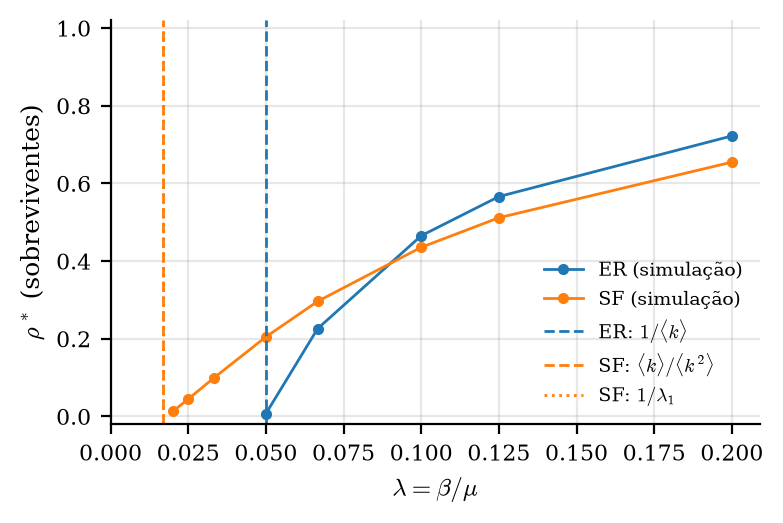

In [24]:
fig, ax = plt.subplots(figsize=(3.8, 2.5))

for nome in redes_varredura:
    mus = sorted(curvas[nome])
    lam = np.array([beta_q3 / mu for mu in mus])
    rho = np.array([curvas[nome][mu]['rho_cond_media_tavg'] for mu in mus])
    ax.plot(lam, rho, 'o-', ms=3, lw=1, label=f'{nome} (simulação)')

# limiares teóricos
ax.axvline(1 / medidas_er_q3['<k>'], color='C0', ls='--', lw=1,
           label=r'ER: $1/\langle k\rangle$')
ax.axvline(k1_q2 / k2_q2, color='C1', ls='--', lw=1,
           label=r'SF: $\langle k\rangle/\langle k^2\rangle$')
ax.axvline(1 / lam1_q2, color='C1', ls=':', lw=1,
           label=r'SF: $1/\lambda_1$')

ax.set_xlabel(r'$\lambda = \beta/\mu$')
ax.set_ylabel(r'$\rho^*$ (sobreviventes)')
ax.set_ylim(-0.02, 1.02)
ax.set_xlim(left=0)                         # deixa visíveis os limiares da SF (~0,026)
ax.legend(loc='lower right', fontsize=7)
salvar_fig(fig, 'q2_rho_lambda')
plt.show()

Limiares críticos $\lambda_c$ de cada rede (linhas verticais na figura):

| Rede | $\langle k\rangle$ | $\langle k^2\rangle$ | $\lambda_1$ | $\lambda_c$ hom | $\lambda_c$ het | $\lambda_c$ quenched |
|---|---|---|---|---|---|---|
| ER | 19,97 | 418,49 | 21,01 | 0,0501 | 0,0477 | 0,0476 |
| SF | 19,58 | 1152,74 | 58,71 | 0,0511 | 0,0170 | 0,0170 |

In [25]:
# Linhas da tabela de limiares: copiar a saída para o markdown abaixo da figura de 2.3
for nome, m in [('ER', medidas_er_q3), ('SF', medidas_q2)]:
    print(f"| {nome} | {fmt(m['<k>'], '.2f')} | {fmt(m['<k^2>'], '.2f')} | {fmt(m['lambda_1'], '.2f')} | "
          f"{fmt(1 / m['<k>'], '.4f')} | {fmt(m['<k>'] / m['<k^2>'], '.4f')} | {fmt(1 / m['lambda_1'], '.4f')} |")

| ER | 19,97 | 418,49 | 21,01 | 0,0501 | 0,0477 | 0,0476 |
| SF | 19,58 | 1152,74 | 58,71 | 0,0511 | 0,0170 | 0,0170 |


**Discussão.**

- **Limiar.** A SF sustenta a epidemia com infecção mais fraca que a ER. Na ER, 91% das execuções se extinguem em $\lambda=0{,}05$ e todas abaixo disso, como prevê $\lambda_c\approx1/\langle k\rangle\approx0{,}05$. Na SF, 45% ainda sobrevivem em $\lambda=0{,}033$ ($\rho^*=0{,}100$), e a extinção só é total para $\lambda\le0{,}0167$, perto de $\langle k\rangle/\langle k^2\rangle=0{,}017$.
- **Forma da curva.** Na ER, $\rho^*$ dispara logo acima do limiar; na SF, cresce devagar, porque perto do limiar a infecção sobrevive quase só entre os hubs. Longe do limiar a ordem se inverte (0,72 na ER × 0,66 na SF em $\lambda=0{,}2$): 54% dos nós da SF têm $k\le12$ e, com poucos vizinhos, se infectam menos que os nós da ER, que têm $k\approx20$.
- **Tamanho finito.** Perto do limiar, a fração de extintas depende de $N$ e de $T$. Além disso, para $\gamma=2{,}5$ o limiar da SF só é diferente de zero porque a rede é finita (ver 2.4).

### 2.4 Aprofundamento (opcional) — campo médio por grau
$\dfrac{d\rho_k}{dt}=-\mu\rho_k+\beta k(1-\rho_k)\Theta,\quad \Theta=\dfrac{1}{\langle k\rangle}\sum_k kP(k)\rho_k$

**Demonstração:** estado endêmico existe $\iff \beta/\mu>\langle k\rangle/\langle k^2\rangle$.

No estado estacionário, $d\rho_k/dt=0$ dá $\rho_k=\dfrac{\beta k\Theta}{\mu+\beta k\Theta}$. Substituindo na definição de $\Theta$, o problema vira uma equação de ponto fixo, $\Theta=F(\Theta)$, com $F(\Theta)=\dfrac{1}{\langle k\rangle}\sum_k kP(k)\dfrac{\beta k\Theta}{\mu+\beta k\Theta}$. $\Theta=0$ é sempre solução. Como $F$ é crescente e côncava e $F(1)<1$, a curva $F(\Theta)$ cruza a reta $\Theta$ uma segunda vez (solução endêmica) se e somente se começa acima dela, isto é, se $F'(0)>1$. Como $F'(0)=\dfrac{\beta\langle k^2\rangle}{\mu\langle k\rangle}$, isso equivale a $\beta/\mu>\langle k\rangle/\langle k^2\rangle$.

**Discussão:** o limiar depende de $\langle k^2\rangle$, que para $\gamma\le3$ cresce sem limite com o maior grau: $\langle k^2\rangle\sim k_{max}^{3-\gamma}$. Com o corte natural $k_{max}\sim N^{1/(\gamma-1)}$, para $\gamma=2{,}5$ temos $\langle k^2\rangle\sim N^{1/3}$, logo $\langle k\rangle/\langle k^2\rangle\to0$ quando $N\to\infty$: numa rede infinita, qualquer $\lambda>0$ mantém a epidemia. Nossa rede tem limiar finito (0,017) porque é finita e o corte $k_{max}=450$ limita $\langle k^2\rangle$.

In [26]:
# (opcional) verificação numérica: <k^2> em função de N (ou k_max) para gamma = 2.5, limiar <k>/<k^2> resultante

## 3. Questão 3 — Imunização prévia
**Rede e parâmetros.** Rede SF da Q2 ($N=10^4$), com $\beta=0{,}01$ e $\mu=0{,}1$, o caso (a) da Q2, bem acima do limiar ($R_0^{het}=5{,}89$). Imunizar é remover o vértice da dinâmica; as 5 sementes são sorteadas entre os não imunizados.

**Critério de extinção.** Uma fração $f$ impede a endemia se, em 100 execuções, nenhuma tem infectados em $T=500$ (critério principal do enunciado; a alternativa $\rho^*<10^{-3}$ não foi usada). Reportamos como $f_c$ a menor fração testada que satisfaz o critério, isto é, o limite superior da bisseção.

### 3.0 Estratégias e bisseção
Cada estratégia define uma **ordem de remoção** na rede original, e imunizar uma fração $f$ é remover os $\operatorname{round}(fN)$ primeiros vértices dessa ordem:

- **(a) aleatória:** permutação uniforme (falha aleatória);
- **(b) hubs:** grau decrescente, com desempate pelo identificador (ataque dirigido);
- **(c) conhecidos:** sorteia-se um vértice e imuniza-se um vizinho aleatório dele, ainda não imunizado; isso escolhe vértices com probabilidade proporcional ao grau.

Com ordens fixas, os conjuntos imunizados são aninhados ($f_1<f_2\Rightarrow A(f_1)\subset A(f_2)$): as curvas em $f$ são comparáveis e a teoria é avaliada nos mesmos conjuntos da simulação. As ordens (a) e (c) usam sementes próprias (342 e 343), independentes das da epidemia.

A bisseção busca o menor $f$ que satisfaz o critério, com resolução 0,05 (aleatória) e 0,01 (hubs e conhecidos). Em cada $f$ rodamos 100 execuções no subgrafo residual, com sementes da epidemia fixas para cada $f$; a avaliação para na primeira execução sobrevivente.

In [27]:
# --- 3.0 Estratégias de imunização -------------------------------------------

def imunizar_aleatoria(G, rng):
    '''Ordem uniformemente aleatória (falha aleatória).'''
    return list(rng.permutation(list(G.nodes)))


def imunizar_hubs(G):
    '''Ordem por grau decrescente na rede original (ataque dirigido).
    Desempate pelo identificador do vértice, para reprodutibilidade.'''
    return [u for u, k in sorted(G.degree, key=lambda x: (-x[1], x[0]))]


def imunizar_conhecidos(G, rng, alvo=None, max_tent=100):
    '''Ordem por "conhecidos": sorteia um vértice u e imuniza um vizinho
    aleatório de u ainda não imunizado. O vizinho é uniforme entre os contatos,
    então P(imunizar v) ∝ k_v e o grau médio dos imunizados tende a
    <k²>/<k> (amostragem enviesada por grau).'''
    nos = list(G.nodes)
    alvo = len(nos) if alvo is None else min(int(alvo), len(nos))
    imunes, ordem = set(), []
    tent = 0
    while len(ordem) < alvo and tent < max_tent * max(alvo, 1):
        tent += 1
        u = nos[rng.integers(len(nos))]
        viz = [v for v in G[u] if v not in imunes]
        if not viz:
            continue
        v = viz[rng.integers(len(viz))]
        ordem.append(v)
        imunes.add(v)
    if len(ordem) < alvo:
        # completa a ordem; só é usada se f chegar perto de 1
        restantes = [u for u in nos if u not in imunes]
        rng.shuffle(restantes)
        ordem.extend(restantes[:alvo - len(ordem)])
    return ordem


# Sementes das ordens (independentes das sementes da epidemia)
SEED_ORDENS = {'aleatoria': SEED_BASE + 300, 'conhecidos': SEED_BASE + 301}
ordens_q3 = {
    'aleatoria': imunizar_aleatoria(G_q2, np.random.default_rng(SEED_ORDENS['aleatoria'])),
    'hubs': imunizar_hubs(G_q2),
    'conhecidos': imunizar_conhecidos(G_q2, np.random.default_rng(SEED_ORDENS['conhecidos'])),
}
ROTULOS_Q3 = {'aleatoria': '(a) Aleatória', 'hubs': '(b) Hubs',
              'conhecidos': '(c) Conhecidos'}
CORES_Q3 = {'aleatoria': 'C0', 'hubs': 'C1', 'conhecidos': 'C2'}
MARCADORES_Q3 = {'aleatoria': 'o', 'hubs': 's', 'conhecidos': '^'}

In [28]:
# Conferência das ordens de remoção (grau médio dos primeiros vértices removidos)
# --- Testes de sanidade das ordens -------------------------------------------
N_q3_ord = G_q2.number_of_nodes()
print(f"Rede Q3: N={N_q3_ord}, <k>={medidas_q2['<k>']:.2f}, "
      f"<k²>={medidas_q2['<k^2>']:.2f}, κ=<k²>/<k>="
      f"{medidas_q2['<k^2>'] / medidas_q2['<k>']:.2f}")
print("\n| Estratégia | <k> primeiros 10% | <k> primeiros 20% | <k> primeiros 40% |")
print("|---|---|---|---|")
for nome, ordem in ordens_q3.items():
    assert len(ordem) == N_q3_ord and len(set(ordem)) == N_q3_ord, nome
    graus = np.array([G_q2.degree(u) for u in ordem], dtype=float)
    m10, m20, m40 = (graus[:max(1, int(round(q * N_q3_ord)))].mean()
                     for q in (0.1, 0.2, 0.4))
    print(f"| {ROTULOS_Q3[nome]} | {m10:.1f} | {m20:.1f} | {m40:.1f} |")

# aninhamento dos prefixos (propriedade por construção)
ordem = ordens_q3['aleatoria']
for f1, f2 in [(0.1, 0.2), (0.2, 0.5), (0.5, 0.8)]:
    a = set(ordem[:int(round(f1 * N_q3_ord))])
    b = set(ordem[:int(round(f2 * N_q3_ord))])
    assert a <= b, (f1, f2)
print("\nPrefixos aninhados: OK")

# checagem qualitativa: hubs > conhecidos > aleatória no começo da ordem
m = {nome: np.mean([G_q2.degree(u) for u in ordem[:max(1, N_q3_ord // 10)]])
     for nome, ordem in ordens_q3.items()}
print(f"Grau médio dos 10% primeiros: aleatória={m['aleatoria']:.1f}, "
      f"hubs={m['hubs']:.1f}, conhecidos={m['conhecidos']:.1f}")
if not (m['hubs'] > m['conhecidos'] > m['aleatoria']):
    print("AVISO: a ordem qualitativa hubs > conhecidos > aleatória não se manteve nesta rede.")
if m['conhecidos'] < 0.6 * medidas_q2['<k^2>'] / medidas_q2['<k>']:
    print("AVISO: grau médio dos 'conhecidos' abaixo do esperado (<k²>/<k>); "
          "verifique a amostragem por vizinho.")

Rede Q3: N=10000, <k>=19.58, <k²>=1152.74, κ=<k²>/<k>=58.86

| Estratégia | <k> primeiros 10% | <k> primeiros 20% | <k> primeiros 40% |
|---|---|---|---|
| (a) Aleatória | 20.8 | 20.0 | 19.8 |
| (b) Hubs | 76.7 | 51.6 | 34.2 |
| (c) Conhecidos | 45.9 | 37.7 | 29.3 |

Prefixos aninhados: OK
Grau médio dos 10% primeiros: aleatória=20.8, hubs=76.7, conhecidos=45.9


In [29]:
# --- 3.0 Busca do f_c por bisseção -------------------------------------------
# Critério principal (literal do enunciado): nenhuma das n_runs execuções tem
# infectados em t=T. O teste é feito no subgrafo residual, com sementes
# sorteadas entre os não imunizados. A mesma semente é usada para o mesmo f
# (números aleatórios comuns): o oráculo é determinístico em f, mas as n_runs
# trajetórias continuam sendo n_runs sorteios independentes da epidemia.

N_q3, N_RUNS_q3, T_q3 = N_q2, N_RUNS_q2, T_q2
beta_q3_imun, mu_q3_imun = 0.01, 0.1
VERSAO_Q3 = 'v1'


def arquivo_cache_q3(nome, seed_ordem, realizacao=0):
    return (f'results/q3{VERSAO_Q3}_cache_{nome}_s{seed_ordem}_r{realizacao}'
            f'_N{N_q3}_beta{beta_q3_imun}_mu{mu_q3_imun}_T{T_q3}_n{N_RUNS_q3}.pkl')


def carregar_cache_q3(caminho):
    if os.path.exists(caminho):
        with open(caminho, 'rb') as fh:
            return pickle.load(fh)
    return {}


def salvar_cache_q3(caminho, cache):
    with open(caminho, 'wb') as fh:
        pickle.dump(cache, fh)


def semente_f(estrategia, realizacao, f):
    '''Entropia determinística para (estratégia, realização da ordem, f).'''
    codigo = {'aleatoria': 1, 'hubs': 2, 'conhecidos': 3}[estrategia]
    return (SEED_BASE, codigo, int(realizacao), int(round(f * 1_000_000)))


def extincao_total(G, f, ordem, beta, mu, seed_f, n_runs=N_RUNS_q3, T=T_q3,
                   fail_fast=False):
    '''Roda n_runs execuções com fração f imunizada e devolve um resumo compacto.
    Se fail_fast e alguma execução sobrevive, para na primeira sobrevivente
    (usado apenas na bisseção).'''
    N = G.number_of_nodes()
    n = min(int(round(f * N)), N)
    G_res = G.subgraph(set(G.nodes) - set(ordem[:n])).copy()
    # A cópia herdaria um cache de estrutura do grafo original; o subgrafo tem
    # outra estrutura, então descartamos o cache.
    G_res.graph.pop('_sis_estrutura', None)
    n_res = G_res.number_of_nodes()

    if n_res == 0:
        return dict(extinguiu=True, n=n, f_real=n / N, n_res=0,
                    n_rodadas=0, rodadas_completas=True,
                    n_sobreviventes=0, frac_infectadas=0.0,
                    rho_cond=0.0, rho_geral=0.0, tempo_tipico=None)

    rng_seeds = np.random.SeedSequence(seed_f).spawn(n_runs)
    series, tempos = [], []
    for r in range(n_runs):
        s, t = simular_sis(G_res, beta, mu, T,
                           np.random.default_rng(rng_seeds[r]))
        series.append(s)
        tempos.append(t)
        if fail_fast and s[-1] > 0:
            return dict(extinguiu=False, n=n, f_real=n / N, n_res=n_res,
                        n_rodadas=r + 1, rodadas_completas=False,
                        n_sobreviventes=None, frac_infectadas=None,
                        rho_cond=None, rho_geral=None, tempo_tipico=None)

    resumo = resumir_execucoes(series, tempos, n_res)
    return dict(
        extinguiu=resumo['n_sobreviventes'] == 0,
        n=n, f_real=n / N, n_res=n_res,
        n_rodadas=n_runs, rodadas_completas=True,
        n_sobreviventes=resumo['n_sobreviventes'],
        frac_infectadas=resumo['n_sobreviventes'] / n_runs,
        rho_cond=resumo['rho_cond_media_tavg'],
        rho_geral=resumo['rho_geral_media_tavg'],
        tempo_tipico=resumo['tempo_tipico_extincao'],
    )


def avaliar_f(G, f, ordem, estrategia, realizacao, beta, mu, n_runs, T,
              fail_fast, cache, caminho_cache):
    '''Avalia o critério em f, reaproveitando o cache quando possível.'''
    chave = f'{f:.6f}'
    r = cache.get(chave)
    # Um resultado incompleto (fail_fast) só serve a outra chamada com fail_fast.
    if r is not None and (r['rodadas_completas'] or fail_fast):
        return r
    r = extincao_total(G, f, ordem, beta, mu,
                       seed_f=semente_f(estrategia, realizacao, f),
                       n_runs=n_runs, T=T, fail_fast=fail_fast)
    if r['rodadas_completas']:
        cache[chave] = r
        if caminho_cache:
            salvar_cache_q3(caminho_cache, cache)
    return r


def bissecao_f(G, ordem, estrategia, resolucao, beta, mu, realizacao=0,
               T=T_q3, n_runs=N_RUNS_q3, f_lo=0.0, f_hi=0.99,
               fail_fast=True, cache=None, caminho_cache=None):
    '''Menor f (na malha da bisseção) que satisfaz o critério.
    Retorna f_hi (limite superior conservador), o histórico e o nº de
    violações de monotonicidade observadas no histórico.'''
    if cache is None:
        cache = {}
    hist = []
    while f_hi - f_lo > resolucao:
        f = 0.5 * (f_lo + f_hi)
        r = avaliar_f(G, f, ordem, estrategia, realizacao, beta, mu,
                      n_runs, T, fail_fast, cache, caminho_cache)
        hist.append((f, r))
        if r['extinguiu']:
            f_hi = f
        else:
            f_lo = f
    pares = sorted((f, r['extinguiu']) for f, r in hist)
    violacoes = sum(1 for a, b in zip(pares, pares[1:]) if a[1] and not b[1])
    return f_hi, hist, violacoes


RESOLUCAO_Q3 = {'aleatoria': 0.05, 'hubs': 0.01, 'conhecidos': 0.01}
resultados_q3 = {}
for nome, ordem in ordens_q3.items():
    t0 = time.perf_counter()
    caminho = arquivo_cache_q3(nome, SEED_ORDENS.get(nome, 0), 0)
    cache = carregar_cache_q3(caminho)
    f_c, hist, viol = bissecao_f(
        G_q2, ordem, nome, RESOLUCAO_Q3[nome],
        beta_q3_imun, mu_q3_imun, realizacao=0,
        cache=cache, caminho_cache=caminho)
    resultados_q3[nome] = dict(f_c=f_c, hist=hist, violacoes=viol,
                               resolucao=RESOLUCAO_Q3[nome],
                               n=int(round(f_c * N_q3)),
                               n_aval=len(hist),
                               tempo=time.perf_counter() - t0)

In [30]:
# Linhas da tabela da bisseção: copiar a saída para o markdown "Resultados da bisseção"
# (o limiar verdadeiro está entre o maior f sem extinção e f_c)
for nome, r in resultados_q3.items():
    f_lo = max((f for f, rr in r['hist'] if not rr['extinguiu']), default=0.0)
    r_hi = next(rr for f, rr in r['hist'] if f == r['f_c'])
    print(f"| {ROTULOS_Q3[nome]} | {fmt(r['f_c'], '.3f')} | ({fmt(f_lo, '.3f')}; {fmt(r['f_c'], '.3f')}] "
          f"| {r['n']} | {r_hi['n_res']} | {fmt(r['resolucao'], 'g')} |")
print('violações de monotonicidade:', {n: r['violacoes'] for n, r in resultados_q3.items()})

| (a) Aleatória | 0,773 | (0,742; 0,773] | 7734 | 2266 | 0,05 |
| (b) Hubs | 0,101 | (0,093; 0,101] | 1005 | 8995 | 0,01 |
| (c) Conhecidos | 0,333 | (0,325; 0,333] | 3326 | 6674 | 0,01 |
violações de monotonicidade: {'aleatoria': 0, 'hubs': 0, 'conhecidos': 0}


**Resultados da bisseção** (100 execuções, $T=500$). O limiar verdadeiro está entre o maior $f$ testado sem extinção e $f_c$; $N_{res}$ é o número de vértices restantes. Nenhuma inversão (extinção num $f$ e sobrevivência num $f$ maior) apareceu no histórico.

| Estratégia | $f_c$ | Intervalo do limiar | $n=f_cN$ | $N_{res}$ | Resolução |
|---|---|---|---|---|---|
| (a) Aleatória | 0,773 | (0,742; 0,773] | 7734 | 2266 | 0,05 |
| (b) Hubs | 0,101 | (0,093; 0,101] | 1005 | 8995 | 0,01 |
| (c) Conhecidos | 0,333 | (0,325; 0,333] | 3326 | 6674 | 0,01 |

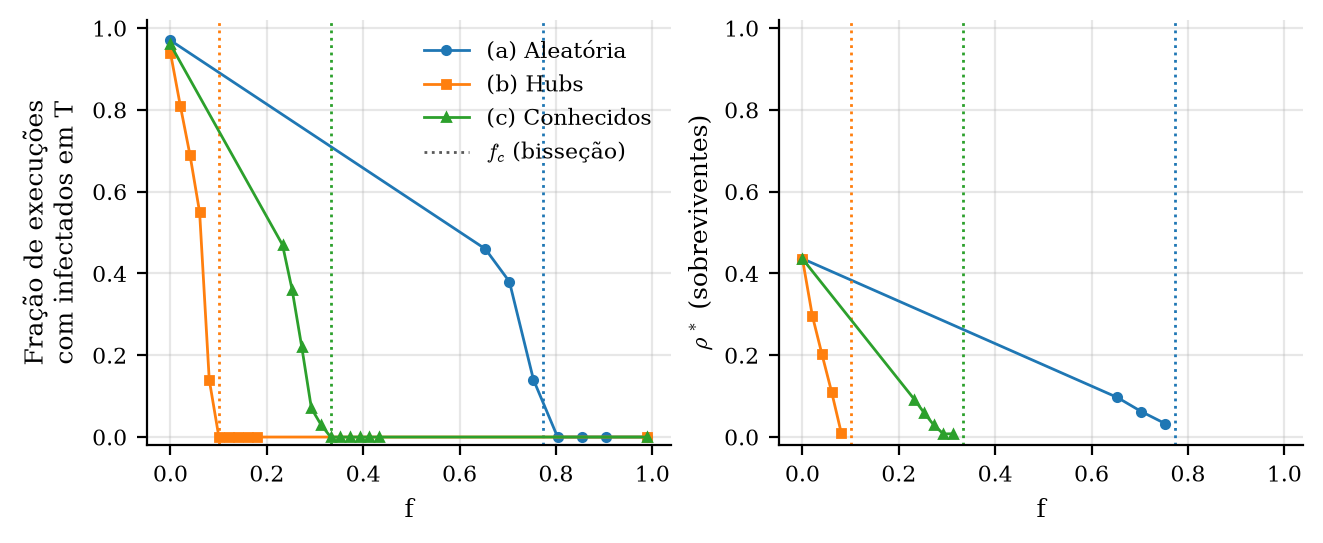

In [31]:
# --- 3.0 Figura: fração de execuções infectadas e rho* em função de f --------
def grade_em_torno(f_c, passo, meia_largura=0.1):
    '''Grade de f em torno de f_c, sempre incluindo 0 e 0,99.'''
    lo = max(0.0, f_c - meia_largura)
    hi = min(0.99, f_c + meia_largura)
    grade = np.arange(lo, hi + 0.5 * passo, passo)
    return np.unique(np.round(np.concatenate(([0.0], grade, [0.99])), 6))


PASSO_GRADE = {'aleatoria': 0.05, 'hubs': 0.02, 'conhecidos': 0.02}
LARGURA_GRADE = {'aleatoria': 0.12, 'hubs': 0.08, 'conhecidos': 0.10}
grades_q3 = {}
for nome, r in resultados_q3.items():
    grade = grade_em_torno(r['f_c'], PASSO_GRADE[nome], LARGURA_GRADE[nome])
    caminho = arquivo_cache_q3(nome, SEED_ORDENS.get(nome, 0), 0)
    cache = carregar_cache_q3(caminho)
    resultados = {}
    for f in grade:
        resultados[float(f)] = avaliar_f(
            G_q2, float(f), ordens_q3[nome], nome, 0,
            beta_q3_imun, mu_q3_imun, N_RUNS_q3, T_q3,
            fail_fast=False, cache=cache, caminho_cache=caminho)
    grades_q3[nome] = (grade, resultados)

fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.6), sharex=True)
for nome, (grade, res) in grades_q3.items():
    fs = np.array(sorted(res))
    frac = np.array([res[f]['frac_infectadas'] for f in fs], dtype=float)
    rho = np.array([np.nan if res[f]['rho_cond'] is None else res[f]['rho_cond']
                    for f in fs], dtype=float)
    axs[0].plot(fs, frac, marker=MARCADORES_Q3[nome], ms=3, lw=1,
                color=CORES_Q3[nome], label=ROTULOS_Q3[nome])
    axs[1].plot(fs, rho, marker=MARCADORES_Q3[nome], ms=3, lw=1,
                color=CORES_Q3[nome], label=ROTULOS_Q3[nome])
    for ax in axs:
        ax.axvline(resultados_q3[nome]['f_c'], color=CORES_Q3[nome], ls=':', lw=1)

axs[0].set_xlabel('f')
axs[0].set_ylabel('Fração de execuções\ncom infectados em T')
axs[0].set_ylim(-0.02, 1.02)
axs[1].set_xlabel('f')
axs[1].set_ylabel(r'$\rho^*$ (sobreviventes)')
axs[1].set_ylim(-0.02, 1.02)
axs[0].plot([], [], color='0.35', ls=':', lw=1, label='$f_c$ (bisseção)')
axs[0].legend(loc='best')
salvar_fig(fig, 'q3_frac_rho')
plt.show()

### 3.1 Teoria
No limiar epidêmico espera-se $\beta\lambda_1(f)/\mu\approx1$, com $\lambda_1(f)$ o maior autovalor da adjacência do subgrafo residual, calculado nos mesmos conjuntos da simulação. Para a remoção aleatória há ainda duas previsões fechadas: o campo médio por grau, $\kappa(f)=(1-f)\langle k^2\rangle/\langle k\rangle+f=\mu/\beta$, e o homogêneo, $f=1-1/R_0^{hom}$. Nesta rede, $\kappa_0=\langle k^2\rangle/\langle k\rangle=58{,}86$, $\mu/\beta=10$ e $R_0^{hom}=1{,}96$.

| Estratégia | $f_c$ (sim) | $\beta\lambda_1(f_c)/\mu$ | $f_c$ ($\lambda_1$) | $f_c$ ($\kappa$) | $f_c$ (hom.) |
|---|---|---|---|---|---|
| (a) Aleatória | 0,773 | 1,25 | 0,824 | 0,844 | 0,489 |
| (b) Hubs | 0,101 | 1,02 | 0,105 | — | — |
| (c) Conhecidos | 0,333 | 1,03 | 0,348 | — | — |

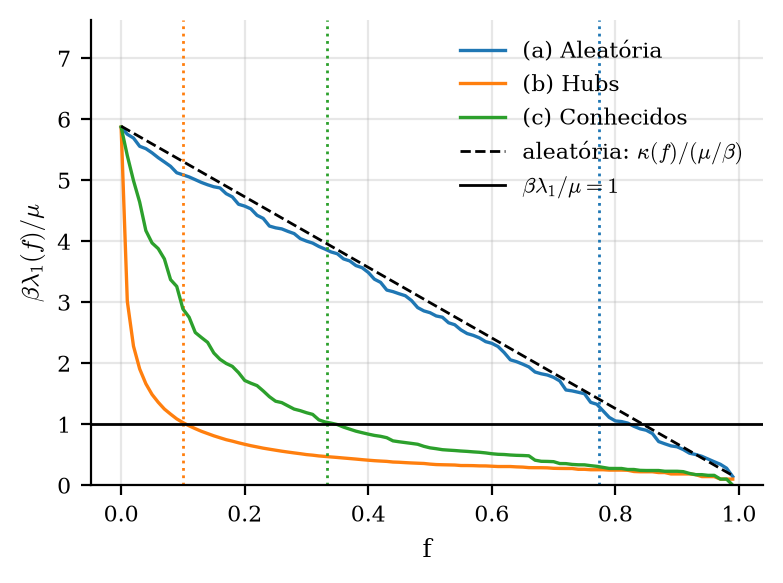

In [32]:
# --- 3.1 Teoria: lambda_1(f) da rede residual -------------------------------
def lambda1_residual(G):
    '''Maior autovalor da adjacência; 0 para grafos vazios ou sem arestas.'''
    n = G.number_of_nodes()
    if n <= 1 or G.number_of_edges() == 0:
        return 0.0
    A = nx.to_scipy_sparse_array(G, format='csr', dtype=float)
    try:
        return float(eigsh(A, k=1, which='LA', return_eigenvectors=False)[0])
    except Exception:
        # fallback para grafos pequenos/patológicos
        return float(np.linalg.eigvalsh(A.toarray())[-1])


def cruzamento(fs, ys, nivel=1.0):
    '''Primeiro f (interpolado) em que ys cruza nivel de cima para baixo.'''
    fs = np.asarray(fs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    if ys[0] <= nivel:
        return float(fs[0])
    for i in range(1, len(fs)):
        if ys[i - 1] > nivel >= ys[i]:
            t = (ys[i - 1] - nivel) / (ys[i - 1] - ys[i])
            return float(fs[i - 1] + t * (fs[i] - fs[i - 1]))
    return None


fs_teo = np.round(np.linspace(0, 0.99, 100), 4)
teoria_q3 = {}
for nome, ordem in ordens_q3.items():
    lam = []
    for f in fs_teo:
        n = int(round(f * N_q3))
        G_res = G_q2.subgraph(set(G_q2.nodes) - set(ordem[:n])).copy()
        lam.append(lambda1_residual(G_res))
    teoria_q3[nome] = np.array(lam)

kappa0 = medidas_q2['<k^2>'] / medidas_q2['<k>']
f_kappa = (kappa0 - mu_q3_imun / beta_q3_imun) / (kappa0 - 1)
f_kappa = float(np.clip(f_kappa, 0.0, 1.0))
R0_hom = beta_q3_imun * medidas_q2['<k>'] / mu_q3_imun
f_hom = float(max(0.0, 1 - 1 / R0_hom))
kappa_f = (1 - fs_teo) * kappa0 + fs_teo
f_kappa_curva = cruzamento(fs_teo, kappa_f, nivel=mu_q3_imun / beta_q3_imun)

fig, ax = plt.subplots(figsize=(3.8, 2.8))
for nome, lam in teoria_q3.items():
    ax.plot(fs_teo, beta_q3_imun * lam / mu_q3_imun, lw=1.2,
            color=CORES_Q3[nome], label=ROTULOS_Q3[nome])
    ax.axvline(resultados_q3[nome]['f_c'], color=CORES_Q3[nome], ls=':', lw=1)
if f_kappa_curva is not None:
    ax.plot(fs_teo, kappa_f / (mu_q3_imun / beta_q3_imun), 'k--', lw=1,
            label=r'aleatória: $\kappa(f)/(\mu/\beta)$')
ax.axhline(1, color='k', ls='-', lw=1, label=r'$\beta\lambda_1/\mu=1$')
ax.set_xlabel('f')
ax.set_ylabel(r'$\beta\lambda_1(f)/\mu$')
ax.set_ylim(0, 1.3 * beta_q3_imun * teoria_q3['aleatoria'][0] / mu_q3_imun)
ax.legend(loc='best')
salvar_fig(fig, 'q3_lambda1')
plt.show()

In [33]:
# Valores de referência e linhas da tabela de teoria: copiar para o markdown "3.1 Teoria"
print(f"κ0 = <k²>/<k> = {fmt(kappa0, '.2f')}; μ/β = {fmt(mu_q3_imun / beta_q3_imun, '.1f')}; "
      f"R0_hom = β<k>/μ = {fmt(R0_hom, '.2f')}")
f_kappa_txt = "—" if f_kappa_curva is None else fmt(f_kappa_curva, '.3f')
print(f"f_c (κ, curva) = {f_kappa_txt} (fórmula {fmt(f_kappa, '.3f')}); "
      f"f_c (homogêneo) = {fmt(f_hom, '.3f')}")
print("\n| Estratégia | $f_c$ (sim) | $\\beta\\lambda_1(f_c)/\\mu$ | "
      "$f_c$ ($\\lambda_1$) | $f_c$ (κ) | $f_c$ (hom.) |")
print("|---|---|---|---|---|---|")
for nome, r in resultados_q3.items():
    n_c = int(round(r['f_c'] * N_q3))
    G_c = G_q2.subgraph(set(G_q2.nodes) - set(ordens_q3[nome][:n_c])).copy()
    lam_c = lambda1_residual(G_c)
    razao = beta_q3_imun * lam_c / mu_q3_imun
    f_lam = cruzamento(fs_teo, beta_q3_imun * teoria_q3[nome] / mu_q3_imun)
    fk, fh = ((f_kappa_txt, f"{fmt(f_hom, '.3f')}")
              if nome == 'aleatoria' else ('—', '—'))
    print(f"| {ROTULOS_Q3[nome]} | {fmt(r['f_c'], '.3f')} | {fmt(razao, '.2f')} | "
          f"{'—' if f_lam is None else fmt(f_lam, '.3f')} | {fk} | {fh} |")

κ0 = <k²>/<k> = 58,86; μ/β = 10,0; R0_hom = β<k>/μ = 1,96
f_c (κ, curva) = 0,844 (fórmula 0,844); f_c (homogêneo) = 0,489

| Estratégia | $f_c$ (sim) | $\beta\lambda_1(f_c)/\mu$ | $f_c$ ($\lambda_1$) | $f_c$ (κ) | $f_c$ (hom.) |
|---|---|---|---|---|---|
| (a) Aleatória | 0,773 | 1,25 | 0,824 | 0,844 | 0,489 |


| (b) Hubs | 0,101 | 1,02 | 0,105 | — | — |
| (c) Conhecidos | 0,333 | 1,03 | 0,348 | — | — |


**Discussão.**

- **$\lambda_1$ descreve o limiar.** No $f_c$ simulado, $\beta\lambda_1/\mu$ fica entre 1,02 e 1,25, perto de 1, nas três estratégias. A previsão por $\lambda_1$ fica sempre um pouco acima do valor simulado (0,824, 0,105 e 0,348): a simulação extingue com menos imunização que o limiar determinístico, o que é esperado, porque numa rede finita a epidemia pode morrer por flutuação mesmo um pouco acima do limiar, e o critério "0 de 100" capta essas extinções.
- **Previsões fechadas (aleatória).** O homogêneo ($f_c=0{,}489$) subestima muito a imunização necessária, porque ignora a cauda de graus. O campo médio por grau corrige isso e dá 0,844, quase o valor de $\lambda_1$ (0,824) e perto do simulado (0,773): a heterogeneidade de graus é o ingrediente dominante. Para hubs e conhecidos não há fórmula fechada, mas $\lambda_1$ do subgrafo residual continua acertando.

### 3.2 Robustez

- **Falhas aleatórias × ataques dirigidos.** A remoção aleatória precisa de $f_c\approx0{,}77$; o ataque aos hubs, de $f_c\approx0{,}10$, quase 8 vezes menos. É a assinatura da rede livre de escala: a conectividade se concentra em poucos hubs, então a rede tolera falhas aleatórias mas é frágil a ataques a eles, como na percolação.
- **Por que os conhecidos ficam no meio.** Escolher o vizinho de um vértice sorteado favorece vértices de grau alto: o grau médio dos primeiros 10% imunizados é 45,9, perto de $\langle k^2\rangle/\langle k\rangle\approx58{,}9$, contra 20,8 na aleatória e 76,7 nos hubs. A estratégia atinge parte dos hubs sem conhecer os graus, e por isso dá $f_c\approx0{,}33$, entre as outras duas.
- **Percolação (SIR) × limiar do SIS.** Na remoção aleatória, destruir o componente gigante exigiria $\kappa(f)=2$, ou $f\approx0{,}98$; o SIS só precisa de $\kappa(f)=\mu/\beta=10$, ou $f\approx0{,}84$. O simulado (0,773) segue o limiar espectral, e não o de percolação: no SIS a epidemia some quando $\beta\lambda_1/\mu<1$, mesmo com a rede ainda conexa. Por isso, imunizar para o SIS custa menos do que fragmentar a rede.

In [34]:
# --- 3.2 Robustez: aleatoriedade da própria intervenção ----------------------
# Repetimos a bisseção para R ordens independentes das estratégias estocásticas.
# A resolução é um pouco mais grossa que a da 3.0 para manter o custo baixo;
# o objetivo aqui é a dispersão, não refinar o f_c principal.
FAZER_ROBUSTEZ = True
R_ROB = 5 if not MODO_TESTE else 3
RESOLUCAO_ROB = {'aleatoria': 0.02, 'conhecidos': 0.02}
robustez_q3 = {}

if FAZER_ROBUSTEZ:
    for nome in ['aleatoria', 'conhecidos']:
        f_cs, f_lams = [], []
        for r in range(R_ROB):
            seed_ord = SEED_BASE + 500 + 100 * r + (0 if nome == 'aleatoria' else 1)
            rng_ord = np.random.default_rng(seed_ord)
            ordem_r = (imunizar_aleatoria(G_q2, rng_ord) if nome == 'aleatoria'
                       else imunizar_conhecidos(G_q2, rng_ord))

            caminho = arquivo_cache_q3(nome, seed_ord, r)
            cache = carregar_cache_q3(caminho)
            f_c_r, hist_r, viol_r = bissecao_f(
                G_q2, ordem_r, nome, RESOLUCAO_ROB[nome],
                beta_q3_imun, mu_q3_imun, realizacao=r,
                cache=cache, caminho_cache=caminho)
            f_cs.append(f_c_r)

            # f_c previsto por lambda_1 para a mesma ordem (grade mais grossa)
            fs_r = np.round(np.linspace(0, 0.99, 60), 4)
            lam_r = []
            for f in fs_r:
                n = int(round(f * N_q3))
                G_res = G_q2.subgraph(set(G_q2.nodes) - set(ordem_r[:n])).copy()
                lam_r.append(lambda1_residual(G_res))
            f_lam = cruzamento(fs_r, beta_q3_imun * np.array(lam_r) / mu_q3_imun)
            f_lams.append(np.nan if f_lam is None else f_lam)

        robustez_q3[nome] = dict(f_cs=np.array(f_cs),
                                 f_lams=np.array(f_lams, dtype=float))

In [35]:
# Linhas da tabela de sensibilidade à ordem de remoção: copiar para o markdown de "3.2 Robustez"
for nome, d in robustez_q3.items():
    fc, fl = d['f_cs'], d['f_lams']
    ok = ~np.isnan(fl)
    print(f"| {ROTULOS_Q3[nome]} | {fmt(np.median(fc), '.3f')} ({fmt(fc.min(), '.3f')}–{fmt(fc.max(), '.3f')}) "
          f"| {fmt(np.median(fl[ok]), '.3f')} ({fmt(fl[ok].min(), '.3f')}–{fmt(fl[ok].max(), '.3f')}) |")

| (a) Aleatória | 0,820 (0,789–0,866) | 0,859 (0,832–0,893) |
| (c) Conhecidos | 0,340 (0,340–0,356) | 0,363 (0,356–0,391) |


**Sensibilidade à ordem de remoção.** As estratégias (a) e (c) dependem do sorteio da ordem. Repetindo a bisseção para 5 ordens independentes (resolução 0,02), mediana e faixa de $f_c$:

| Estratégia | $f_c$ simulado | $f_c$ ($\lambda_1$) |
|---|---|---|
| (a) Aleatória | 0,820 (0,789–0,866) | 0,859 (0,832–0,893) |
| (c) Conhecidos | 0,340 (0,340–0,356) | 0,363 (0,356–0,391) |

Entre ordens, $f_c$ varia ~0,08 na aleatória e ~0,02 nos conhecidos, bem menos que as diferenças entre estratégias, e a previsão por $\lambda_1$ fica de novo ~0,04 (aleatória) e ~0,02 (conhecidos) acima do simulado. A ordem dos hubs é determinística. Com 100 execuções, "0 sobreviventes" só garante $P_{sobrev}\lesssim3\%$ (95% de confiança), então diferenças de um ou dois passos da malha não são significativas.

## Anexo A — Código
> O código completo está neste notebook (`.ipynb`), executável do início ao fim (*Restart & Run All*). Entregar junto ao PDF, com `requirements.txt`.

In [36]:
# Registro final de execução (tempo total, versões, semente)
import matplotlib
print(f"Tempo total: {(time.time() - T_INICIO) / 60:.1f} min")
print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| networkx", nx.__version__, "| matplotlib", matplotlib.__version__, "|", platform.platform())
print("SEED_BASE =", SEED_BASE, "| N =", N, "| T =", T, "| N_RUNS =", N_RUNS)
print("Cache em results/:", sorted(os.listdir("results")))

Tempo total: 5.3 min
Python 3.14.3 | numpy 2.5.5 | scipy 1.18.1 | networkx 3.7 | matplotlib 3.11.2 | Windows-11-10.0.26300-SP0
SEED_BASE = 42 | N = 10000 | T = 500 | N_RUNS = 100
Cache em results/: ['q1_er_s42_mu0.1_beta0.02_T500_n100.pkl', 'q1_er_s42_mu0.1_beta0.02_T500_n100_N10000.pkl', 'q1_er_s42_mu0.3_beta0.02_T500_n100.pkl', 'q1_er_s42_mu0.3_beta0.02_T500_n100_N10000.pkl', 'q1_er_s42_mu0.4_beta0.02_T500_n100.pkl', 'q1_er_s42_mu0.4_beta0.02_T500_n100_N10000.pkl', 'q1_er_s42_mu0.5_beta0.02_T500_n100.pkl', 'q1_er_s42_mu0.5_beta0.02_T500_n100_N10000.pkl', 'q2_curva_ER_s42_N10000_mu0.05_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N10000_mu0.08_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N10000_mu0.15_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N10000_mu0.1_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N10000_mu0.2_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N10000_mu0.3_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N10000_mu0.4_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N10000_mu0.5_beta0.01_T500_n100.

## Exportação do PDF final (célula de estudo)

1. *Restart & Run All*; conferir que não há `NotImplementedError`/`TODO` visíveis.
2. Marcar rascunhos com tag `study` e blocos de código com `hide-code` (já pré-marcados neste template).
3. Exportar, por exemplo:
```bash
jupyter nbconvert --to pdf simulacao_nb.ipynb --template-file tex/relatorio.tex.j2 --output-dir tex \
  --TagRemovePreprocessor.remove_cell_tags='{"study"}' \
  --TagRemovePreprocessor.remove_input_tags='{"hide-code"}'
```
(alternativa se não houver LaTeX: `--to html`, abrir no navegador e imprimir em PDF; ou `--to webpdf`.)
4. Conferir limite de **1 página por questão** e legibilidade das figuras.
5. Anexar o `.ipynb` + `requirements.txt` + pasta `figs/` (se pedido).

**Checklist final**
- [ ] Declaração de IA visível
- [ ] Todas as tabelas preenchidas
- [ ] Todas as figuras com eixos/legendas/unidades
- [ ] Sementes e versões informadas
- [ ] Opcionais assinalados como tal